> ## 🎤 강사 스크립트 · 이 강사용 노트북 사용법
>
> 이 노트북은 **학생용 `D27_Pipecat기초_실습.ipynb`의 모든 셀을 그대로 담고**, 사이사이에 **🎤 강사 스크립트 셀**을 끼워 넣은 것입니다. 수업 화면에는 학생용을, 강사 화면에는 이 노트북을 띄우세요.
>
> | 표시 | 뜻 |
> |---|---|
> | 🎯 | 이 블록에서 학생이 가져가야 할 한 가지 |
> | 🗣️ | 그대로 읽어도 되는 강사 멘트 |
> | 🍎 | 일상 비유 |
> | 🖥️ | 화면 시연 |
> | ❓ | 학생에게 던지는 질문 → 예상 답 |
> | 🆘 | 빈칸에서 막힌 학생에게 주는 힌트 |
> | ⚠️ | 자주 막히는 지점 · 오개념 · 오류 |
> | 🎧 | 반 전체가 같이 들을 소리 (스피커) |
> | ➡️ | 다음 블록으로 넘어가는 연결 멘트 |
>
> **오늘의 수업 방향**: D21 ~ D25에서 함수로 이어 붙인 비서를, 어제(D26) 배운 '조각 · 흐름 · 통로' 위에서 **Pipecat의 틀**로 다시 만듭니다. 핵심 메시지는 **"모든 것은 Frame → 작업자는 받고 · 일하고 · 넘긴다 → 서비스도 작업자다 → Aggregator가 턴과 기록을 맡는다 → Transport만 바꾸면 어디에나 붙는다"** 입니다. 칠판에 쓰는 것은 세 줄: **`await super().process_frame(frame, direction)`**, **`await self.push_frame(frame, direction)`**, **`Pipeline([input, vad, stt, user_agg, llm, tts, output, assistant_agg])`**.
>
> > 🍎 **하루를 꿰는 비유: 컨베이어 벨트 공장.** 상자(Frame) · 작업자(Processor) · 라인 배치도(Pipeline) · 라인 반장(Worker) · 공장장(Runner) · 공장 정문(Transport) · 화재 경보(SystemFrame).
>
> > ⚠️ **API 이름 주의**: 인터넷 예제 대부분이 `PipelineTask` · `PipelineRunner`(1.3.0부터 사용 중단 예정)와 `LLMContext`의 system 메시지(1.9.0부터 `system_instruction` 권장)를 씁니다. 학생이 가져온 예제가 경고를 내면 '옛 이름'이라고 설명하세요. 오늘 노트북은 `pipecat-ai==1.15.0`에서 검증했습니다.
>
> > 🔒 키는 Colab 보안 비밀에만. 화면 공유 중 보안 비밀 창을 열지 마세요. 녹음 · 키는 노션 금지.
>
> > 💡 정답 · 예상 출력 · 힌트는 이 노트북에만 있습니다. **학생에게 배포하지 마세요.**

> ## 🎤 강사 스크립트 · 하루 시간표와 수업 전 점검
>
> #### 하루 시간표 (50분 수업 + 10분 쉬는 시간)
> | 시간 | 교시 | 내용 | 빈칸 | 애니메이션 | 슬라이드 |
> |---|---|---|---|---|---|
> | 0:00–0:50 | 1교시 | 도입, Part 0 설치 · 모델, Part 1 Frame, Part 2 Processor | 1 · 2 · 3 | D27-1 · 2 · 3 | p.1 ~ 7 |
> | 1:00–1:50 | 2교시 | Part 3 Pipeline · Worker · Runner · 방향 · Observer | 4 | D27-4 | p.8 ~ 10 |
> | 2:00–2:50 | 3교시 | Part 4 서비스 (STT · TTS · 루프 막힘 · LLM) | 5 · 6 · 7 | D27-5 · 6 | p.11 ~ 14 |
> | 3:00–3:50 | 4교시 | Part 5 조립 · 턴별 시간, Part 6 Transport · WebSocket, Part 7 정리 | 8 · 9 | D27-7 · 8 · 9 | p.15 ~ 20 |
>
> **진도가 밀릴 때 줄이는 순서** (빈칸 실습은 줄이지 않습니다)
> 1. Part 2 '깜빡' 실험은 강사 시연만 (3초 대기)
> 2. Part 3 Observer 셀은 표 ①만 보고 넘어가기
> 3. Part 6 WebSocket 셀은 강사 시연 + 학생은 결과표만 확인
>
> #### 수업 전 점검 (전날)
> - [ ] 처음부터 끝까지 한 번 실행(T4, 로컬 Qwen이면 약 10분 · 키가 있으면 약 6분). Part 4 루프 막힘 표, Part 5 대화 기록 · 턴별 시간표, Part 6 응답 시간 캡처
> - [ ] **설치 줄**: `pipecat-ai[websocket]==1.15.0`이 오류 없이 설치되는지(Colab의 protobuf가 6.x로 바뀌는 경고는 정상)
> - [ ] 키가 있다면 강사 계정 키로 **클라우드 LLM 경로**도 한 번 (`OpenAILLMService` + `base_url`). 모델 이름(`MODELS`)이 그날 유효한지 각 회사 문서에서 확인
> - [ ] 스피커 준비 (Part 4 · 5 · 6의 비서 목소리를 반 전체가 같이 듣기)
> - [ ] [animation.html](https://imguru-mooc.github.io/AI_Voice/day27/animation.html) · [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day27/worksheet.html) 탭 열기
>
> #### 오늘 학생들이 가장 많이 막히는 곳
> | 위치 | 증상 | 대응 |
> |---|---|---|
> | 모든 Pipecat 셀 | 셀이 끝나지 않고 계속 돎 | 대부분 `push_frame` 빼먹음 → StartFrame · EndFrame이 끝까지 못 감. Part 2 '깜빡' 실험을 다시 보여 주기. 그래도 안 되면 런타임 → 실행 중단 |
> | 빈칸 2 · 3 | `super().process_frame` 대신 `super().push_frame` | "부모에게 **보여 주기**(process)와 다음 사람에게 **건네기**(push)는 다른 일" |
> | 빈칸 5 | `return TranscriptionFrame(...)` | `run_stt`는 제너레이터 → `yield`. return을 쓰면 'async generator' 오류 |
> | 빈칸 6 | `await tts(...)` | `tts`는 일반 함수라 await 불가 → `asyncio.to_thread(tts, ...)` |
> | Part 4 LLM | `Connection error` · 401 | 키 이름 · 모델 이름 · 사용량 확인. 안 되면 `PROVIDER = "local"`로 바꾸고 keys 셀부터 다시 |
> | Part 5 | 비서 답이 한 번만 나옴 · ⏰ 메시지 | LLM 오류 확인(위). 로컬 Qwen이 긴 답을 내면 시간이 걸림 → `max_new_tokens` 낮추기 |
> | Part 6 | `Address already in use` | 셀을 두 번 실행 → 런타임 재시작 없이도 `WS_PORT = free_port()`가 새 포트를 잡으므로 셀 전체를 다시 실행 |

# D27. Pipecat 기초: Frame · Processor · Pipeline · Transport로 STT → LLM → TTS 잇기  —  🎤 강사용

**음성 AI 전문가 과정 (160h) | 6주차 M6 실시간 음성 파이프라인 (Pipecat · LiveKit) | 4시간**

## 학습 목표
1. Pipecat에서 모든 것이 **Frame**으로 흐른다는 것을 이해하고, **System · Data · Control** 세 종류를 구분한다.
2. **FrameProcessor**를 직접 만들어 `process_frame` → `push_frame` 규칙을 익히고, 규칙을 어기면 무슨 일이 생기는지 확인한다.
3. **Pipeline · PipelineWorker · WorkerRunner**로 파이프라인을 돌리고, **downstream · upstream** 방향과 **Observer**로 프레임의 여행을 추적한다.
4. 우리 모델(Whisper · Qwen3)과 TTS(Edge 신경망 음성) · 클라우드 LLM을 **STT · TTS · LLM 서비스**로 감싸, 한 줄씩 바꿔 끼울 수 있게 만든다.
5. **Context Aggregator**로 대화 이력을 자동으로 쌓으며 VAD → STT → LLM → TTS 두 턴 대화를 돌리고, 턴마다 걸린 시간을 잰다.
6. **Transport**를 WebSocket으로 바꿔 끼워, D26의 클라이언트처럼 20 ms 조각을 보내고 비서의 목소리를 받는다.

## 오늘의 실습 흐름
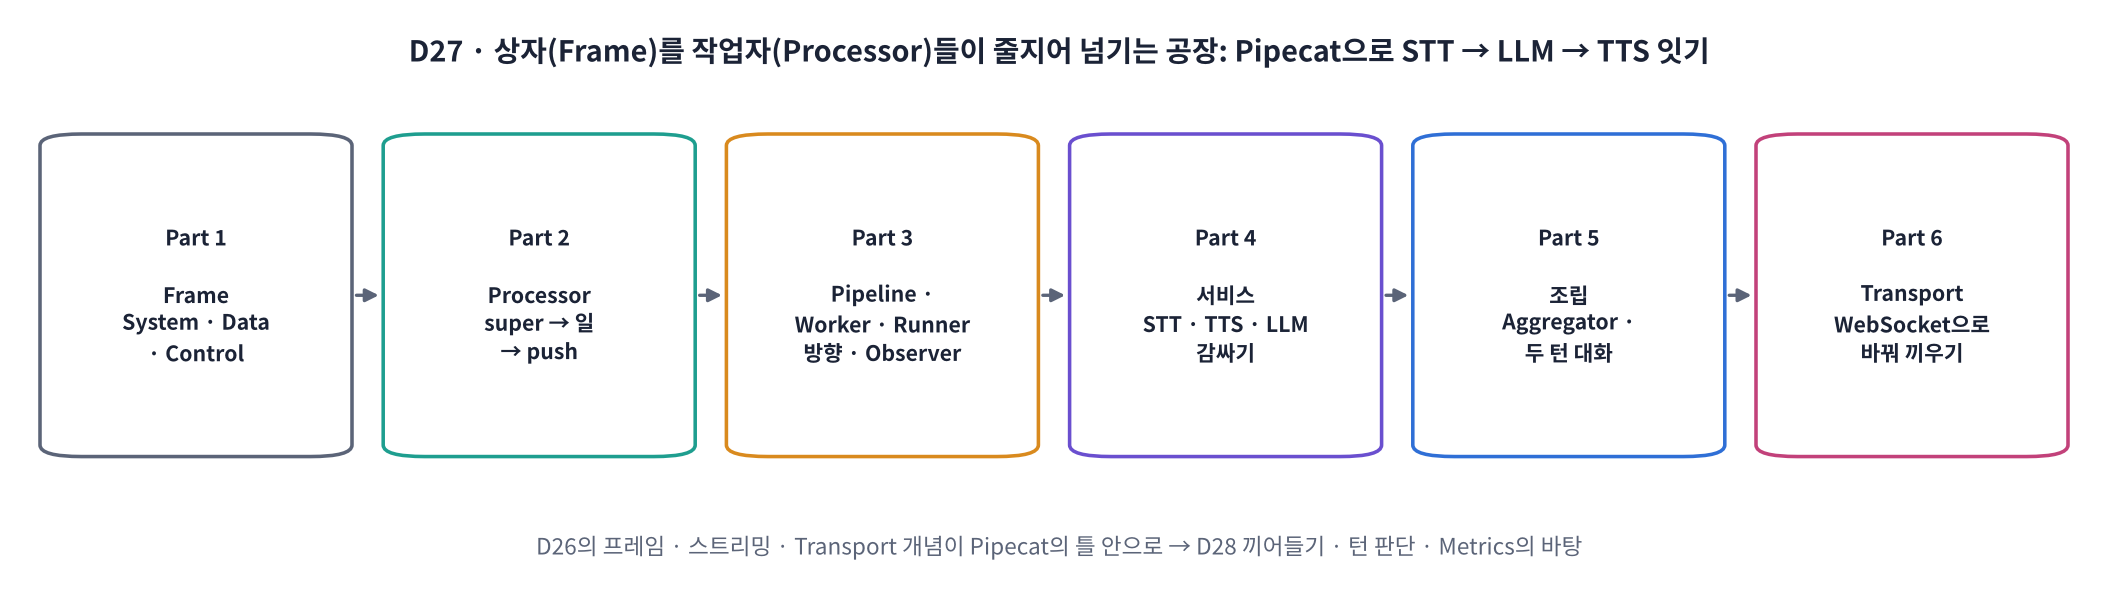

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | Pipecat이 푸는 문제, Frame 세 종류, FrameProcessor 규칙 | Part 0 ~ 2, 워크시트 1교시 | 프레임 분류표 · 숫자 정규화 프로세서 |
| 2교시 | Pipeline · Worker · Runner, 방향(upstream), Observer | Part 3, 워크시트 2교시 | 프레임 여행 기록표 |
| 3교시 | 서비스: STT · TTS · LLM 감싸기, 이벤트 루프를 막지 않기 | Part 4, 워크시트 3교시 | 서비스별 걸린 시간 · 루프 막힘 실험표 |
| 4교시 | 조립(Context Aggregator) · Transport 바꿔 끼우기(WebSocket), 정리 | Part 5 ~ 7, 워크시트 4교시 | 두 턴 대화 기록 · 턴별 시간표 · WebSocket 응답 시간 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day27/animation.html) | 프레임 종류(D27-2) · 프로세서(D27-3) · 방향(D27-4) · 조립(D27-7) · Transport(D27-8) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day27/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 위에서부터 차례로 실행합니다. `!`로 시작하는 줄은 리눅스 명령입니다.
- 🧩 **빈칸 실습** 셀은 `____`를 채우고 실행하면 ✅ 또는 ❌가 나옵니다. 🔑 **정답 및 해설 보기**를 누르면 정답이 펼쳐집니다.
- ✏️ 표시 셀은 값을 **직접 바꿔** 다시 실행해 보는 셀입니다.
- ⏳ Pipecat은 `async`(비동기)로 돌아갑니다. 셀 안의 `await ...`는 Colab에서 그대로 실행됩니다(D26 Part 4와 같음).

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🎧 **들어 보기** | 소리로 확인 |

> ⚙️ **런타임 → T4 GPU**. 🔑 **API 키 (선택, D22와 같음)**: Colab 왼쪽 🔑(보안 비밀)에 `ANTHROPIC_API_KEY` · `OPENAI_API_KEY` · `GEMINI_API_KEY` 중 하나가 있으면 그 LLM을, 없으면 **로컬 Qwen3**를 씁니다. 키는 화면에 출력하지 않습니다.
>
> 🔒 오늘의 WebSocket 서버도 **이 Colab 안(127.0.0.1)** 에서만 열립니다. 녹음 · 키는 노션에 붙이지 마세요.

> 🎬 **애니메이션 D27-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#flow) — Part 1~7 로드맵과 시간 계획

> ## 🎤 강사 스크립트 · 도입  ⏱️ 5분
>
> 🎯 **어제는 소리 조각을 손으로 보냈다. 오늘은 그 조각을 흘려보내는 '공장'을 짓는다.**
>
> 🗣️ "D25 비서를 떠올려 보세요. `stt()` 끝나면 `llm()`, 끝나면 `tts()`. 실시간이 되면 이 줄 세우기가 무너집니다. 듣는 중에 VAD가 돌아야 하고, LLM이 말하는 중에도 귀는 열려 있어야 하고, 끼어들면 모두 멈춰야 하죠. 이걸 매번 손으로 짜는 대신, **'모든 것을 상자에 담아 컨베이어 벨트에 올린다'** 는 한 가지 규칙으로 푸는 게 Pipecat입니다."
>
> 🖥️ [D27-1 오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#flow)

## Part 0. 준비

> 🛠️ **버전 충돌 방지 (D18 ~ D26과 같은 방식)**: Colab 기본 패키지 버전을 고정하고 필요한 것만 추가합니다. Pipecat은 업데이트가 빠르고 이름이 자주 바뀌므로 **수업에서 검증한 `pipecat-ai==1.15.0`** 으로 고정합니다.
>
> ⚠️ Pipecat은 `protobuf` 7 미만을 요구하므로, 오늘은 고정 목록에서 `protobuf`를 뺐습니다(설치 중 protobuf가 6.x로 바뀔 수 있음, 오늘 실습에는 영향 없음).

> ## 🎤 강사 스크립트 · Part 0  ⏱️ 8분
>
> 🖥️ 설치(1 ~ 2분) 동안 슬라이드 p.2 'D25 비서 vs Pipecat 비서'.
>
> ⚠️ 설치 출력에 protobuf 관련 경고가 보이면 정상. `pipecat-ai 1.15.0`이 import 줄 버전에 찍히는지 확인.
>
> ✅ import 셀 마지막 줄: `오후 두 시에 세 명, 주차는 두 시간 무료, 할인 십 퍼센트` (D16 정규화 복습).

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt "pipecat-ai[websocket]==1.15.0"
!pip install -q -c colab_constraints.txt uroman edge-tts
print("✅ 설치 완료")

In [ ]:
import os, re, sys, json, time, random, socket, asyncio, warnings, logging
from dataclasses import dataclass
import numpy as np
import pandas as pd
import librosa
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown
import importlib.metadata as md
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)
from loguru import logger                                # Pipecat은 loguru로 로그를 남김 → 경고 이상만 보이게
logger.remove(); logger.add(sys.stderr, level="WARNING")

from pipecat.frames.frames import (Frame, SystemFrame, DataFrame, ControlFrame, StartFrame, EndFrame, CancelFrame,
    TextFrame, LLMTextFrame, TranscriptionFrame, InputAudioRawFrame, OutputAudioRawFrame, TTSAudioRawFrame, TTSSpeakFrame,
    TTSStartedFrame, TTSStoppedFrame, ErrorFrame, InterruptionFrame, LLMContextFrame, LLMFullResponseStartFrame,
    LLMFullResponseEndFrame, VADUserStartedSpeakingFrame, VADUserStoppedSpeakingFrame, UserStartedSpeakingFrame,
    UserStoppedSpeakingFrame, BotStartedSpeakingFrame, BotStoppedSpeakingFrame)
from pipecat.processors.frame_processor import FrameProcessor, FrameDirection
from pipecat.pipeline.pipeline import Pipeline
from pipecat.pipeline.worker import PipelineWorker, PipelineParams
from pipecat.workers.runner import WorkerRunner
from pipecat.observers.base_observer import BaseObserver, FramePushed

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 16000
print(" · ".join(f"{p} {md.version(p)}" for p in ["pipecat-ai", "torch", "transformers", "websockets"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 (CPU로도 가능)")

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    if len(y): display(Audio(y, rate=sr))
    else: print("   (소리 없음: 위의 경고 · 오류를 확인하세요)")

def silence(sec, sr=SR):
    return np.zeros(int(sec * sr), np.float32)

def free_port():                                         # 비어 있는 포트 번호 하나
    s = socket.socket(); s.bind(("127.0.0.1", 0)); p = s.getsockname()[1]; s.close(); return p

# D16 정규화 (숫자 → 읽는 말): TTS 바로 앞에서 씀
DIGITS = "영일이삼사오육칠팔구"
def sino(n):
    if n == 0: return "영"
    out = ""
    for big in ["", "만", "억", "조"]:
        chunk, n = n % 10000, n // 10000; s = ""
        for i, unit in enumerate(["", "십", "백", "천"]):
            d, chunk = chunk % 10, chunk // 10
            if d: s = ("" if d == 1 and i > 0 else DIGITS[d]) + unit + s
        if s: out = ("" if s == "일" and big == "만" else s) + big + out
        if n == 0: break
    return out
ONES = ["", "한", "두", "세", "네", "다섯", "여섯", "일곱", "여덟", "아홉"]
TENS = ["", "열", "스물", "서른", "마흔", "쉰", "예순", "일흔", "여든", "아흔"]
def native(n): return sino(n) if not 0 < n < 100 else ("스무" if n == 20 else TENS[n // 10] + ONES[n % 10])
NATIVE_COUNTERS = ["시간", "개", "명", "살", "마리", "권", "잔", "병", "장", "달", "시"]
def normalize_ko(t):
    t = re.sub(r"(\d+)\s*(" + "|".join(NATIVE_COUNTERS) + ")", lambda m: native(int(m.group(1))) + " " + m.group(2), t)
    t = re.sub(r"(\d+)\s*%", lambda m: sino(int(m.group(1))) + " 퍼센트", t)
    t = re.sub(r"\d+", lambda m: sino(int(m.group(0))), t)
    return re.sub(r"\s+", " ", t).strip()
print(normalize_ko("오후 2시에 3명, 주차는 2시간 무료, 할인 10%"))

In [ ]:
# 🔊 모델 준비: 받아쓰기 Whisper · 합성 Edge TTS (예비 MMS-TTS, D21 ~ D25와 같음) + 오늘의 사용자 말 두 마디
from transformers import AutoTokenizer, VitsModel, WhisperProcessor, WhisperForConditionalGeneration
import uroman as ur
tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
U = ur.Uroman()
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()

import functools, tempfile
VOICE_BOT, VOICE_USER = "ko-KR-SunHiNeural", "ko-KR-InJoonNeural"   # ✏️ Edge 신경망 음성: 비서 · 사용자 대역
TTS_ENGINE = "edge"                                      # 인터넷 · 서비스 문제로 실패하면 자동으로 "mms"(예비)

@functools.lru_cache(maxsize=512)                        # 같은 문장은 다시 요청하지 않음
def _edge_tts(text, voice):
    import edge_tts
    fd, path = tempfile.mkstemp(suffix=".mp3"); os.close(fd)
    try:
        edge_tts.Communicate(text, voice).save_sync(path)
        return librosa.load(path, sr=SR)[0].astype(np.float32)   # MP3 24 kHz → 16 kHz
    finally:
        os.remove(path)

def _mms_tts(text, seed=0):                              # 예비: MMS-TTS 한국어 VITS (D16)
    set_seed(seed)
    enc = tts_tok(U.romanize_string(text), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        return to_np(tts_model(**enc).waveform[0])

def tts(text, seed=0, voice=None):                       # 글자 → 16 kHz 소리: Edge 신경망 음성, 실패하면 MMS-TTS
    global TTS_ENGINE
    if TTS_ENGINE == "edge":
        try:
            return _edge_tts(text, voice or VOICE_BOT).copy()
        except Exception as e:
            print(f"⚠️ Edge TTS 실패 → MMS-TTS로 전환 ({type(e).__name__}: {str(e)[:80]})"); TTS_ENGINE = "mms"
    return _mms_tts(text, seed)

def user_tts(text, seed=0):                              # 사용자 대역 목소리: 비서와 다른 목소리 (MMS 예비일 때는 3반음 낮춰 구분)
    y = tts(text, seed=seed, voice=VOICE_USER)
    return librosa.effects.pitch_shift(y, sr=SR, n_steps=-3) if TTS_ENGINE == "mms" else y

def stt(y):                                              # 16 kHz 소리 → 글자
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def make_voice(text):                                    # 앞 0.5초 · 뒤 1초 조용함을 붙인 '사용자 말'
    y = np.concatenate([silence(0.5), user_tts(text), silence(1.0)]).astype(np.float32)
    return y / (np.abs(y).max() + 1e-9) * 0.8

SAY1 = "안녕하세요 한빛치과죠 다음 주 수요일 오후 두 시에 스케일링 예약하고 싶어요"
SAY2 = "네 이름은 김민준이에요"
VOICE1, VOICE2 = make_voice(SAY1), make_voice(SAY2)
play(VOICE1, SR, "사용자 말 1"); play(VOICE2, SR, "사용자 말 2")
print("받아쓰기 확인:", stt(VOICE1), "/", stt(VOICE2))

> ## 🎤 강사 스크립트 · 사용자 말 두 마디  ⏱️ 3분
>
> 🎧 사용자 말 1(약 4 ~ 5초) · 2(약 2초). Whisper 받아쓰기가 대체로 맞으면 OK (합성 목소리라 한두 글자 틀림은 정상).
>
> 🗣️ "오늘은 마이크 대신 이 두 마디를 '실시간 속도로' 흘려 넣습니다. 진짜 마이크는 D32에서 브라우저로 붙입니다."

In [ ]:
# 🔑 LLM 고르기 (D22와 같음): 키가 있으면 클라우드, 없으면 로컬 Qwen3
def secret(name):
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception:
        pass
    return os.environ.get(name) or None

MODELS = {"claude": "claude-haiku-5-5",                 # ✏️ 모델 이름은 수업 당일 각 회사 문서에서 확인
          "openai": "gpt-6-luna",
          "gemini": "gemini-3.5-flash-lite",
          "local": "Qwen/Qwen3-1.7B" if GPU else "Qwen/Qwen3-0.6B"}
KEYS = {"claude": "ANTHROPIC_API_KEY", "openai": "OPENAI_API_KEY", "gemini": "GEMINI_API_KEY"}
BASE_URLS = {"claude": "https://api.anthropic.com/v1/",                      # 세 회사 모두 'OpenAI 호환' 주소를 제공
             "openai": None,
             "gemini": "https://generativelanguage.googleapis.com/v1beta/openai/"}
AVAILABLE = [p for p in ["claude", "openai", "gemini"] if secret(KEYS[p])] + ["local"]
PROVIDER = AVAILABLE[0]                                  # ✏️ 바꿔 보기: "local" 등

if PROVIDER == "local":
    from transformers import AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(MODELS["local"])
    llm_model = AutoModelForCausalLM.from_pretrained(MODELS["local"], dtype=torch.float16 if GPU else torch.float32).to(DEVICE).eval()

SYSTEM = ("당신은 한빛치과의 전화 예약 도우미입니다. 음성으로 답하므로 한두 문장의 짧은 구어체로 말하고, "
          "목록 · 기호 · 이모지는 쓰지 않습니다. 예약에는 날짜 · 시간 · 진료 · 이름이 필요하며, 빠진 것이 있으면 하나씩 물어봅니다.")
print("쓸 수 있는 LLM:", AVAILABLE, "→ 오늘 쓸 LLM:", PROVIDER, MODELS[PROVIDER])

> ## 🎤 강사 스크립트 · LLM 고르기  ⏱️ 3분
>
> 🗣️ "세 회사 모두 **OpenAI 호환 주소**를 줍니다. 그래서 오늘은 Pipecat의 `OpenAILLMService` 하나로 `base_url`만 바꿔 셋을 다 씁니다. 실제 서비스에서는 각 회사 전용 서비스(`AnthropicLLMService` 등)가 기능이 더 많습니다(호환 주소는 테스트 · 비교용)."
>
> ✅ `쓸 수 있는 LLM: [...] → 오늘 쓸 LLM: ...`. 키가 없는 학생은 `local`(Qwen3, 처음에 내려받기 1 ~ 2분).
>
> ⚠️ 키 값이 화면에 찍히는 코드는 없습니다. 학생이 `print(secret(...))`를 하지 않게 주의.

## Part 1. Pipecat이 푸는 문제와 Frame 세 종류

D25까지의 비서는 `stt() → llm() → tts()`를 **차례로 부르는 함수**였습니다. 실시간이 되면 할 일이 갑자기 늘어납니다: 20 ms마다 소리 조각이 들어오고(D26), 말 시작 · 끝을 감지하고, 받아쓰기가 끝나는 즉시 LLM을 부르고, LLM이 첫 글자를 내자마자 TTS를 시작하고, **사용자가 끼어들면 모두 멈춰야** 합니다(D28).

**Pipecat**은 이 모든 것을 **하나의 규칙**으로 풉니다: **모든 것은 Frame(상자)이고, Processor(작업자)들이 줄지어 서서 상자를 받아 → 일하고 → 다음 사람에게 넘긴다.**

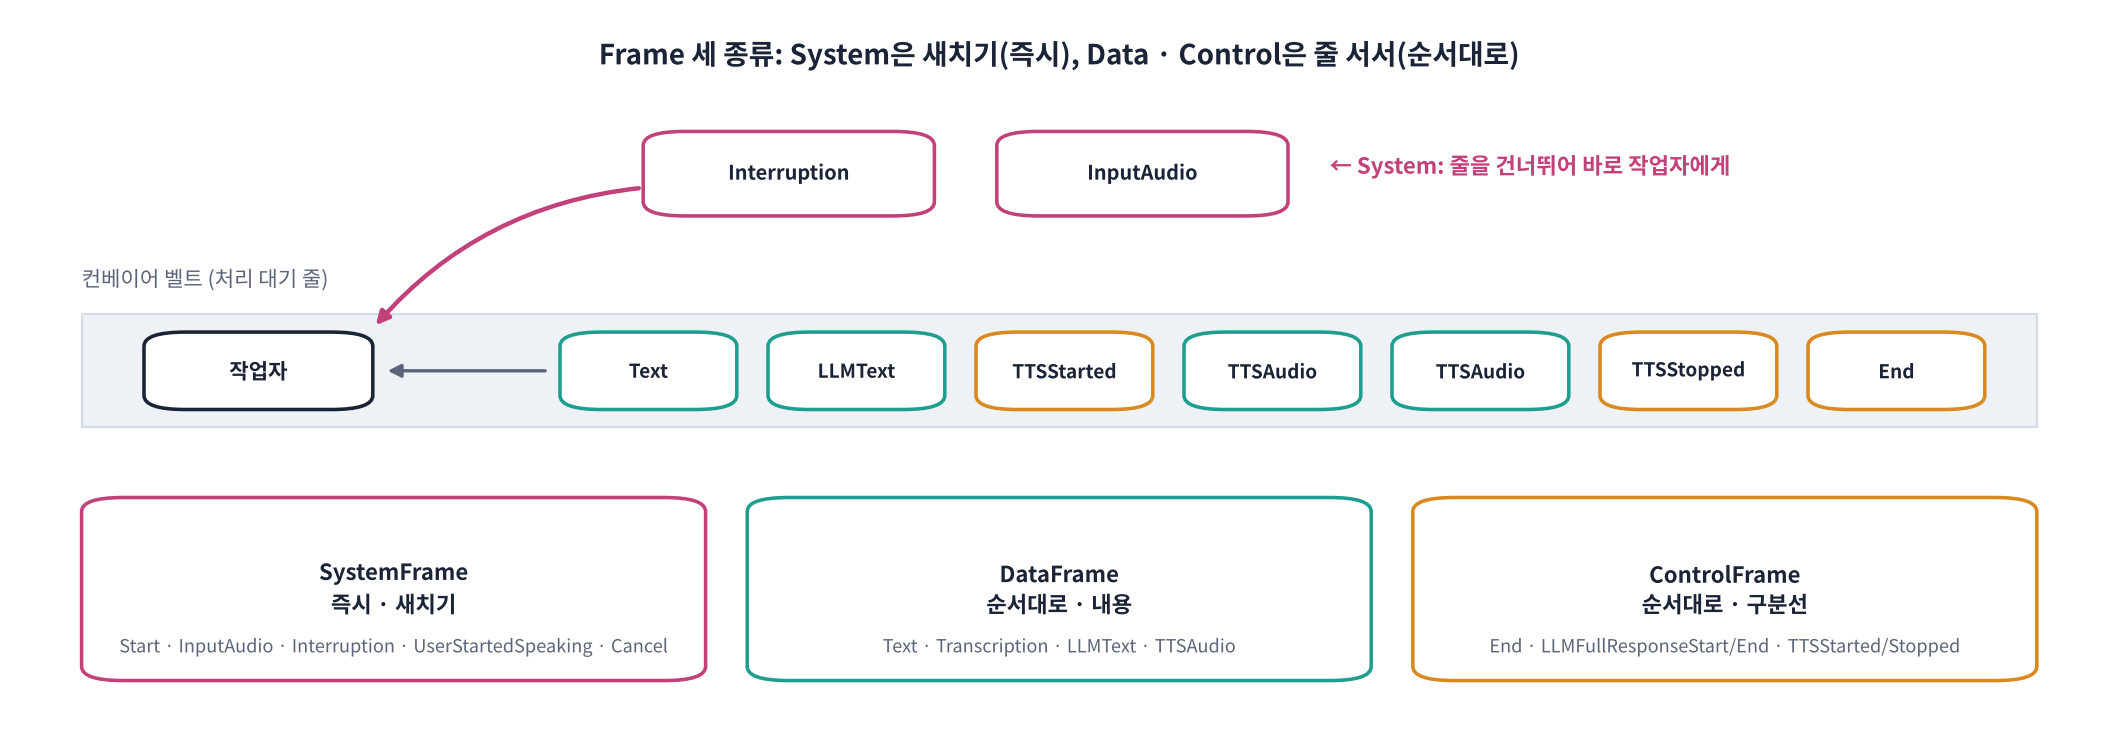

> 💬 **쉽게 말하면**: 소리 조각도, 받아쓴 글자도, LLM의 한 토큰도, "말 시작했어요" 신호도 모두 **Frame**이라는 같은 모양의 상자에 담겨 흐릅니다.

> 🍎 **비유: 공장 컨베이어 벨트.** 벨트 위로 상자(Frame)가 흘러가고, 작업자(Processor)는 자기 상자만 열어 일하고 나머지는 그대로 다음 사람에게 넘깁니다. 화재 경보(SystemFrame)는 벨트를 기다리지 않고 **바로** 전달됩니다.

| 종류 | 처리 방식 | 대표 Frame | 하는 일 |
|---|---|---|---|
| **SystemFrame** | 줄을 서지 않고 **바로** (새치기) | `StartFrame` · `InputAudioRawFrame` · `InterruptionFrame` · `UserStartedSpeakingFrame` · `CancelFrame` | 시작 · 마이크 소리 · 끼어들기 같은 급한 신호 |
| **DataFrame** | 들어온 **순서대로** | `TextFrame` · `TranscriptionFrame` · `LLMTextFrame` · `TTSAudioRawFrame` | 실제 내용 (글자 · 소리) |
| **ControlFrame** | 들어온 **순서대로** | `EndFrame` · `LLMFullResponseStartFrame` · `TTSStartedFrame` · `TTSStoppedFrame` | 내용 사이의 구분선 · 흐름 신호 |

> 📐 **핵심 식 하나**: **System = 즉시, Data · Control = 순서대로.** 마이크 소리(`InputAudioRawFrame`)가 System인 이유는 앞의 작업(예: LLM 생성)이 끝날 때까지 **귀를 막고 있으면 안 되기 때문**입니다.

> 🎬 **애니메이션 D27-2:** [Frame 세 종류](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#frames) — 상자 색으로 System · Data · Control 구분, 새치기 보기

### 🧩 빈칸 실습 1: Frame 분류기
`SystemFrame`이면 "System", **내용을 담은 상자의 부모 클래스**이면 "Data", 나머지는 "Control"로 나누는 함수를 완성하세요.

> ## 🎤 강사 스크립트 · Part 1 Frame  ⏱️ 8분
>
> 🎯 **System = 즉시(새치기), Data · Control = 순서대로.**
>
> 🖥️ [D27-2 Frame 세 종류](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#frames): 벨트에 상자가 줄 서 있을 때 Interruption이 새치기하는 장면.
>
> 🍎 "화재 경보는 택배 줄 뒤에 서지 않습니다."
>
> ❓ "LLM이 답을 만드는 5초 동안 마이크 조각이 줄 뒤에서 기다리면?" → 그동안 사용자가 '잠깐만요'라고 해도 못 들음 → 그래서 InputAudioRawFrame은 System.

In [ ]:
# 🧩 빈칸 실습 1: Frame이 어느 종류인지 판정
def kind(f):
    if isinstance(f, SystemFrame):
        return "System"
    if isinstance(f, ____):                                                       # 빈칸 1: 내용(글자 · 소리)을 담는 Frame의 부모
        return "Data"
    return "Control"

chunk = (VOICE1[:320] * 32767).astype(np.int16).tobytes()          # D26의 20 ms 조각 = 640 바이트
SAMPLES = [
    (StartFrame(), "파이프라인 시작 (설정값을 싣고 맨 앞에서 출발)"),
    (InputAudioRawFrame(audio=chunk, sample_rate=SR, num_channels=1), "마이크 20 ms 조각"),
    (VADUserStartedSpeakingFrame(), "VAD: 말소리 시작"),
    (TranscriptionFrame(text=SAY1, user_id="", timestamp=""), "STT 결과 (받아쓴 문장)"),
    (LLMFullResponseStartFrame(), "LLM 답 시작 표시"),
    (LLMTextFrame(text="네, "), "LLM이 낸 글자 조각 (토큰)"),
    (TTSAudioRawFrame(audio=chunk, sample_rate=SR, num_channels=1, context_id="t1"), "TTS가 만든 소리 조각"),
    (InterruptionFrame(), "사용자가 끼어듦 → 모두 멈춰! (D28)"),
    (EndFrame(), "파이프라인을 '정상적으로' 끝내기"),
]
FRAMES = pd.DataFrame([dict(Frame=type(f).__name__, 종류=kind(f), 설명=d, id=f.id) for f, d in SAMPLES])
display(FRAMES)
check([kind(f) for f, _ in SAMPLES] == ["System", "System", "System", "Data", "Control", "Data", "Data", "System", "Control"],
      hint="빈칸 1 = DataFrame")

> ## 🎤 강사 스크립트 · 🧩 빈칸 1  ⏱️ 4분
>
> 🆘 "System이 아니고, 내용을 담는 상자의 부모" → `DataFrame`.
>
> ✅ 표 9줄: System 4개(Start · InputAudio · VADUserStarted · Interruption), Data 3개(Transcription · LLMText · TTSAudio), Control 2개(LLMFullResponseStart · End), ✅.
>
> 🗣️ "id 열을 보세요. 상자마다 번호가 있어서 Part 3에서 추적할 수 있습니다."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
if isinstance(f, DataFrame):   # 빈칸 1
    return "Data"
```

**해설**: Pipecat의 모든 Frame은 `SystemFrame` · `DataFrame` · `ControlFrame` 중 하나를 부모로 둡니다(`InputAudioRawFrame`처럼 소리를 담아도 **급해서** System인 예외가 있음). `TranscriptionFrame` · `LLMTextFrame`은 `TextFrame`의 자식이고 `TextFrame`은 `DataFrame`의 자식이므로 `isinstance(f, DataFrame)`이 참입니다. 모든 Frame은 고유한 `id`와 `name`(예: `TextFrame#3`)을 가져서, Part 3에서 같은 상자가 어디를 지나가는지 추적할 수 있습니다.

</details>

**❓ 생각해 보기**: 마이크 조각(InputAudioRawFrame)은 System인데, TTS가 만든 소리 조각(TTSAudioRawFrame)은 Data입니다. 둘 다 '소리'인데 왜 다를까요?

<details>
<summary>답 보기</summary>

**들어오는 소리**는 기다리게 하면 안 됩니다. LLM이 답을 만드는 동안에도 VAD가 '사용자가 다시 말하기 시작함'을 알아채야 끼어들기(D28)가 가능하니까요. 반대로 **나가는 소리**는 **순서가 생명**입니다. '네, 예약'과 '도와드릴게요'의 조각 순서가 바뀌면 안 되고, 앞 문장의 `TTSStoppedFrame`(Control)보다 먼저 지나가야 합니다. 그래서 '급한 것은 System, 순서가 중요한 것은 Data · Control'로 나눕니다.

</details>

> 📝 **워크시트 1교시 (앞 5문항)** 를 지금 풀어 보세요 → [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day27/worksheet.html)

> ## 🎤 강사 스크립트 · 생각해 보기 + 워크시트  ⏱️ 5분
>
> ❓ 들어오는 소리 vs 나가는 소리 → 들어오는 것은 급함(System), 나가는 것은 순서(Data).
>
> 🖥️ [worksheet.html 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day27/worksheet.html) 앞 5문항.

## Part 2. FrameProcessor: 받고 → 일하고 → 넘기기

**FrameProcessor**는 컨베이어 벨트의 작업자입니다. 만드는 법은 딱 하나, `process_frame(frame, direction)`을 다시 쓰는 것입니다.

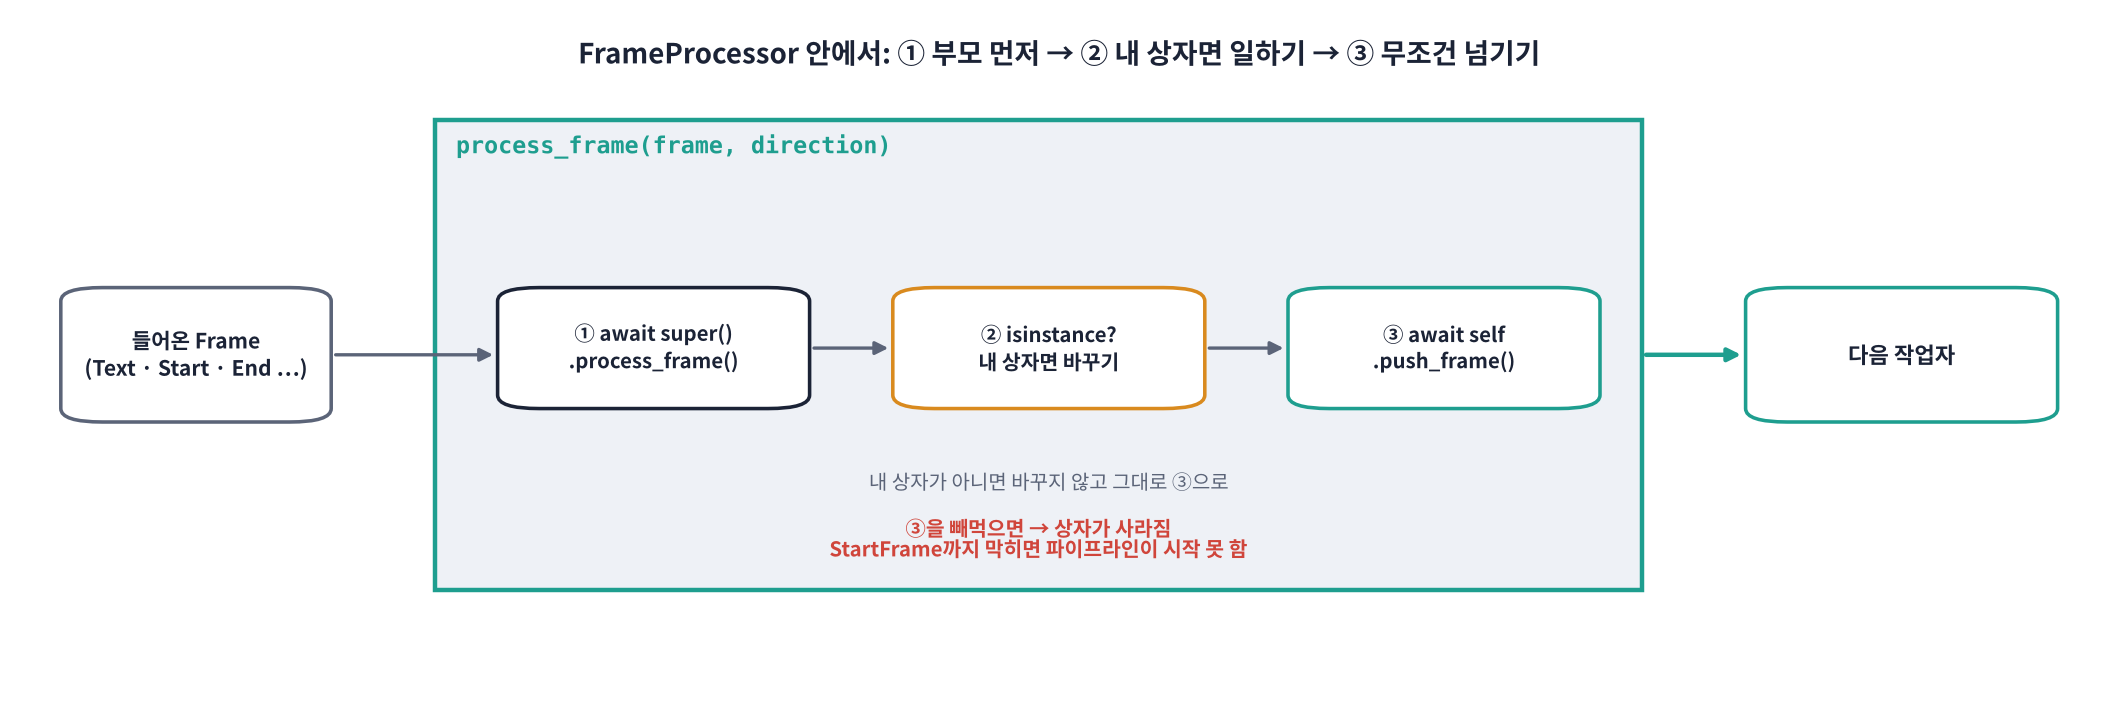

👣 **한 단계씩: 작업자의 세 가지 규칙**
1. **맨 먼저 `await super().process_frame(frame, direction)`**: 부모가 StartFrame 설정 저장 · 끼어들기 처리 같은 공통 일을 합니다.
2. **내 상자면 일한다**: `isinstance(frame, TextFrame)`처럼 골라서 내용을 바꾸거나 새 Frame을 만듭니다.
3. **반드시 `await self.push_frame(frame, direction)`로 넘긴다**: 넘기지 않은 상자는 **그 자리에서 사라집니다**. 내 상자가 아니어도(StartFrame · EndFrame 포함) 그대로 넘겨야 합니다.

> 💬 **쉽게 말하면**: "부모에게 먼저 보여 주고, 내 일만 하고, 무조건 다음 사람에게 넘긴다."

> 🍎 **비유: 릴레이 바통.** 바통(Frame)을 받으면 내 구간만 달리고 반드시 다음 주자에게 건넵니다. 바통을 주머니에 넣어 버리면(`push_frame` 빼먹기) 경기가 거기서 멈춥니다.

| 메서드 | 누가 부르나 | 뜻 |
|---|---|---|
| `process_frame(frame, direction)` | **Pipecat이** 상자가 올 때마다 | 받아서 일하는 곳 (내가 다시 씀) |
| `push_frame(frame, direction)` | **내가** | 다음(또는 이전) 작업자에게 넘기기 |
| `direction` | — | `FrameDirection.DOWNSTREAM`(앞 → 뒤) 또는 `UPSTREAM`(뒤 → 앞, Part 3) |

> 🎬 **애니메이션 D27-3:** [FrameProcessor 안에서](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#proc) — 상자가 들어와 super → 내 일 → push로 나가는 과정, push를 빼먹으면?

먼저 오늘 내내 쓸 **도구 상자**를 준비합니다: 지나가는 Frame을 모두 적어 두는 `Recorder`(받아 적는 작업자), 파이프라인을 한 번 돌리는 `run_frames()`, 실제 마이크처럼 20 ms 조각을 흘려보내는 `mic()`. `run_frames()`의 속은 Part 3에서 뜯어봅니다.

> ## 🎤 강사 스크립트 · Part 2 Processor  ⏱️ 6분
>
> 🎯 **부모 먼저 → 내 일 → 무조건 넘기기.** (칠판에 두 줄)
>
> 🖥️ [D27-3 FrameProcessor 안에서](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#proc): 'push 빼먹기' 버튼으로 상자가 사라지는 장면.
>
> 🍎 릴레이 바통: "바통을 주머니에 넣으면 경기가 멈춥니다."

In [ ]:
# 🧰 도구 상자: Recorder(받아 적기) · run_frames(파이프라인 한 번 돌리기) · mic(가짜 마이크)
QUIET = (InputAudioRawFrame, OutputAudioRawFrame)        # 너무 많아서 표에서는 숨기는 Frame (소리 조각)

class Recorder(FrameProcessor):
    # 지나가는 모든 Frame을 시각과 함께 적고, 소리는 모아 두고, 그대로 넘기는 작업자
    def __init__(self, label="기록", **kwargs):
        super().__init__(**kwargs)
        self.label, self.rows, self.audio, self.t0 = label, [], bytearray(), time.perf_counter()
        self.seen, self.marks = {}, []                   # Frame 종류 → asyncio.Event (기다리기용) · 답마다 소리 시작 위치
    async def process_frame(self, frame, direction):
        await super().process_frame(frame, direction)
        if isinstance(frame, OutputAudioRawFrame):
            self.audio += frame.audio
        if isinstance(frame, LLMFullResponseStartFrame):
            self.marks.append(len(self.audio))
        if not isinstance(frame, QUIET) or not any(r["Frame"] == type(frame).__name__ for r in self.rows[-1:]):
            self.rows.append(dict(시각=round(time.perf_counter() - self.t0, 3), 위치=self.label, Frame=type(frame).__name__,
                                  방향=direction.name, 내용=getattr(frame, "text", None) or getattr(frame, "reason", "")))
        self.seen.setdefault(type(frame), asyncio.Event()).set()
        await self.push_frame(frame, direction)
    async def wait(self, cls, timeout=30):               # 이 종류의 Frame이 지나갈 때까지 기다림
        ev = self.seen.setdefault(cls, asyncio.Event())
        try:
            await asyncio.wait_for(ev.wait(), timeout)
        except asyncio.TimeoutError:
            print(f"⏰ {cls.__name__}가 {timeout}초 안에 오지 않음")
        ev.clear()
    def table(self):
        return pd.DataFrame(self.rows)
    def sound(self, k=None):                             # 모은 소리 전체, 또는 k번째 답의 소리
        a = bytes(self.audio) if k is None else bytes(self.audio)[self.marks[k]:(self.marks + [len(self.audio)])[k + 1]]
        return np.frombuffer(a, np.int16).astype(np.float32) / 32768

async def run_frames(processors, frames=(), feed=None, observers=(), timeout=60, start_timeout=20):
    # processors를 Pipeline으로 묶어 frames를 넣고 → (feed가 있으면 실행) → EndFrame으로 정상 종료
    worker = PipelineWorker(Pipeline(list(processors)), params=PipelineParams(audio_in_sample_rate=SR, audio_out_sample_rate=SR),
                            observers=list(observers), enable_rtvi=False, idle_timeout_secs=None,
                            start_timeout_secs=start_timeout, cancel_timeout_secs=3)
    runner = WorkerRunner(handle_sigint=False)          # Colab(주피터)에서는 Ctrl+C 신호 처리를 끔
    await runner.add_workers(worker)
    t0 = time.perf_counter()
    job = asyncio.ensure_future(runner.run())
    await worker.queue_frames(list(frames))
    if feed: await feed(worker)
    await worker.queue_frame(EndFrame())
    done, _ = await asyncio.wait({job}, timeout=timeout)
    if not done:                                         # 끝나지 않으면 강제 종료 (CancelFrame)
        await runner.cancel(); await job
    return dict(정상종료=bool(done), 걸린시간_초=round(time.perf_counter() - t0, 2))

def mic(*voices, wait=None, timeout=40):
    # 가짜 마이크: 소리를 20 ms 조각(InputAudioRawFrame)으로 '실시간 속도'로 흘려보냄. wait=(recorder, Frame종류)면 말마다 그 Frame까지 기다림
    async def feed(worker):
        for y in voices:
            pcm = (np.clip(y, -1, 1) * 32767).astype(np.int16)
            t0 = time.perf_counter()
            for k, i in enumerate(range(0, len(pcm), 320)):
                await worker.queue_frame(InputAudioRawFrame(audio=pcm[i:i + 320].tobytes(), sample_rate=SR, num_channels=1))
                await asyncio.sleep(max(0, t0 + (k + 1) * 0.02 - time.perf_counter()))
            if wait: await wait[0].wait(wait[1], timeout)
    return feed
print("도구 상자 준비 완료")

> ## 🎤 강사 스크립트 · 도구 상자  ⏱️ 3분
>
> 🗣️ "`Recorder`도 작업자입니다. 규칙 세 개를 그대로 지키죠. 위에서 아래로 읽어 보세요: super → 기록 → push. `run_frames`와 `mic`는 지금은 '파이프라인 한 번 돌리기 버튼', '가짜 마이크'라고만 알아 두세요."
>
> ⚠️ 이 셀은 정의만 하므로 출력은 `도구 상자 준비 완료` 한 줄.

### 🧩 빈칸 실습 2 · 3: 숫자를 읽는 말로 바꾸는 작업자
TTS는 "2시"를 "이 시"로 읽기 쉽습니다(D16). `TextFrame`이 지나가면 `normalize_ko()`로 바꿔 넘기는 작업자를 만드세요.
- 빈칸 2: 부모에게 먼저 보여 주는 메서드 이름 (`super().____`)
- 빈칸 3: 다음 작업자에게 넘기는 메서드 이름 (`self.____`)

In [ ]:
# 🧩 빈칸 실습 2 · 3: 첫 FrameProcessor
class KoNormalizer(FrameProcessor):
    async def process_frame(self, frame, direction):
        await super().____(frame, direction)                                       # 빈칸 2: 규칙 1 (부모 먼저)
        if type(frame) is TextFrame:                     # 규칙 2: 내 상자(그냥 TextFrame)만 골라서 일함
            frame = TextFrame(text=normalize_ko(frame.text))
        await self.____(frame, direction)                                          # 빈칸 3: 규칙 3 (무조건 넘기기)

rec = Recorder("정규화 뒤")
result = await run_frames([KoNormalizer(), rec], [TextFrame(text="네, 다음 주 수요일 오후 2시에 3명 예약됐어요."),
                                                  TextFrame(text="주차는 2시간 무료입니다.")])
print(result)
display(rec.table())
texts = [r["내용"] for r in rec.rows if r["Frame"] == "TextFrame"]
check(result["정상종료"] and texts == ["네, 다음 주 수요일 오후 두 시에 세 명 예약됐어요.", "주차는 두 시간 무료입니다."]
      and rec.rows[0]["Frame"] == "StartFrame" and rec.rows[-1]["Frame"] == "EndFrame", hint="빈칸 2 = process_frame, 빈칸 3 = push_frame")

> ## 🎤 강사 스크립트 · 🧩 빈칸 2 · 3  ⏱️ 8분
>
> 🆘 빈칸 2: "부모의 **같은 이름** 메서드" → `process_frame`. 빈칸 3: "넘기다 = push" → `push_frame`.
>
> ✅ `{'정상종료': True, ...}`, 기록표 4줄: StartFrame → TextFrame(두 시 · 세 명) → TextFrame(두 시간) → EndFrame, ✅.
>
> ❓ "StartFrame · EndFrame은 우리가 넣지 않았는데 왜 있죠?" → Worker가 StartFrame을 보내고, run_frames가 EndFrame을 넣음. 이것도 넘겨야 함.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
await super().process_frame(frame, direction)   # 빈칸 2
...
await self.push_frame(frame, direction)          # 빈칸 3
```

**해설**: 기록표를 보면 **StartFrame이 맨 먼저, EndFrame이 맨 마지막**에 지나갔습니다. 우리가 넣지 않았는데도요. `PipelineWorker`가 시작할 때 StartFrame(샘플링 레이트 등 설정)을 맨 앞에서 보내고, 우리가 넣은 EndFrame이 모든 작업자를 지나 끝에 닿아야 '정상 종료'가 됩니다. 그래서 내 상자가 아니어도 **무조건 넘기는 것**이 규칙 3입니다. `super().process_frame()`을 빼면 부모가 하는 공통 일(StartFrame 설정 저장 · 시작 표시 · 끼어들기 처리)이 빠져서, 수업 준비 중 실험에서는 파이프라인이 **끝나지 않고 멈춰 버렸습니다**. 두 줄은 짝으로 외우세요.

</details>

In [ ]:
# 🧪 실험: 규칙 3을 어기면? (TextFrame만 넘기고 나머지는 '깜빡' → StartFrame이 끝까지 못 감)
class Forgetful(FrameProcessor):
    async def process_frame(self, frame, direction):
        await super().process_frame(frame, direction)
        if isinstance(frame, TextFrame):
            await self.push_frame(TextFrame(text=frame.text + "!"), direction)
        # else: push_frame을 빼먹음 ← 흔한 실수

front, back = Recorder("앞"), Recorder("뒤")
result = await run_frames([front, Forgetful(), back], [TextFrame(text="안녕하세요")], timeout=8, start_timeout=3)
print(f"{result['걸린시간_초']}초 기다리다 Pipecat이 스스로 멈춤 (위의 ERROR 줄: StartFrame이 끝까지 오지 않음) · '뒤'가 받은 Frame 수: {len(back.rows)}")
display(pd.concat([front.table(), back.table()]))

> ## 🎤 강사 스크립트 · 🧪 '깜빡' 실험  ⏱️ 4분
>
> 🖥️ 실행 → 3초 동안 아무 일 없음 → 빨간 ERROR 줄 `timeout waiting for StartFrame … (being blocked somewhere?)`.
>
> ✅ '앞'에는 StartFrame 1줄, '뒤'가 받은 Frame 수 0.
>
> 🗣️ "실제 서비스에서는 이 기다림이 20초입니다. 손님 입장에서는 '전화가 연결됐는데 20초 동안 아무 말도 없다가 끊김'. 증상을 기억해 두세요."

**❓ 생각해 보기**: Forgetful 작업자 뒤에 있는 '뒤' Recorder는 아무것도 받지 못했습니다. StartFrame 하나 안 넘긴 것이 왜 TextFrame까지 막을까요?

<details>
<summary>답 보기</summary>

Pipecat은 **StartFrame이 맨 끝까지 도착해야 파이프라인이 준비됐다**고 판단합니다. 그 전에는 우리가 넣은 상자를 흘려보내지 않고 기다리다가, 시간이 지나면 '어딘가 막혔다(being blocked somewhere?)'며 멈춥니다. 실제 서비스에서는 이 기다림이 20초이므로, **'비서가 아무 말도 안 하고 20초 뒤 끊김'** 이 증상이라면 `push_frame`을 빼먹은 작업자부터 의심하세요.

</details>

> 📝 **워크시트 1교시 (뒤 5문항)** → [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day27/worksheet.html)

> ## 🎤 강사 스크립트 · 워크시트 1교시 마무리  ⏱️ 4분
>
> 🖥️ [worksheet.html 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day27/worksheet.html) 뒤 5문항 → 채점.

## Part 3. Pipeline · Worker · Runner, 그리고 방향(downstream · upstream)

`run_frames()` 안에서 일어난 일을 뜯어봅니다. Pipecat에는 **세 층**이 있습니다.

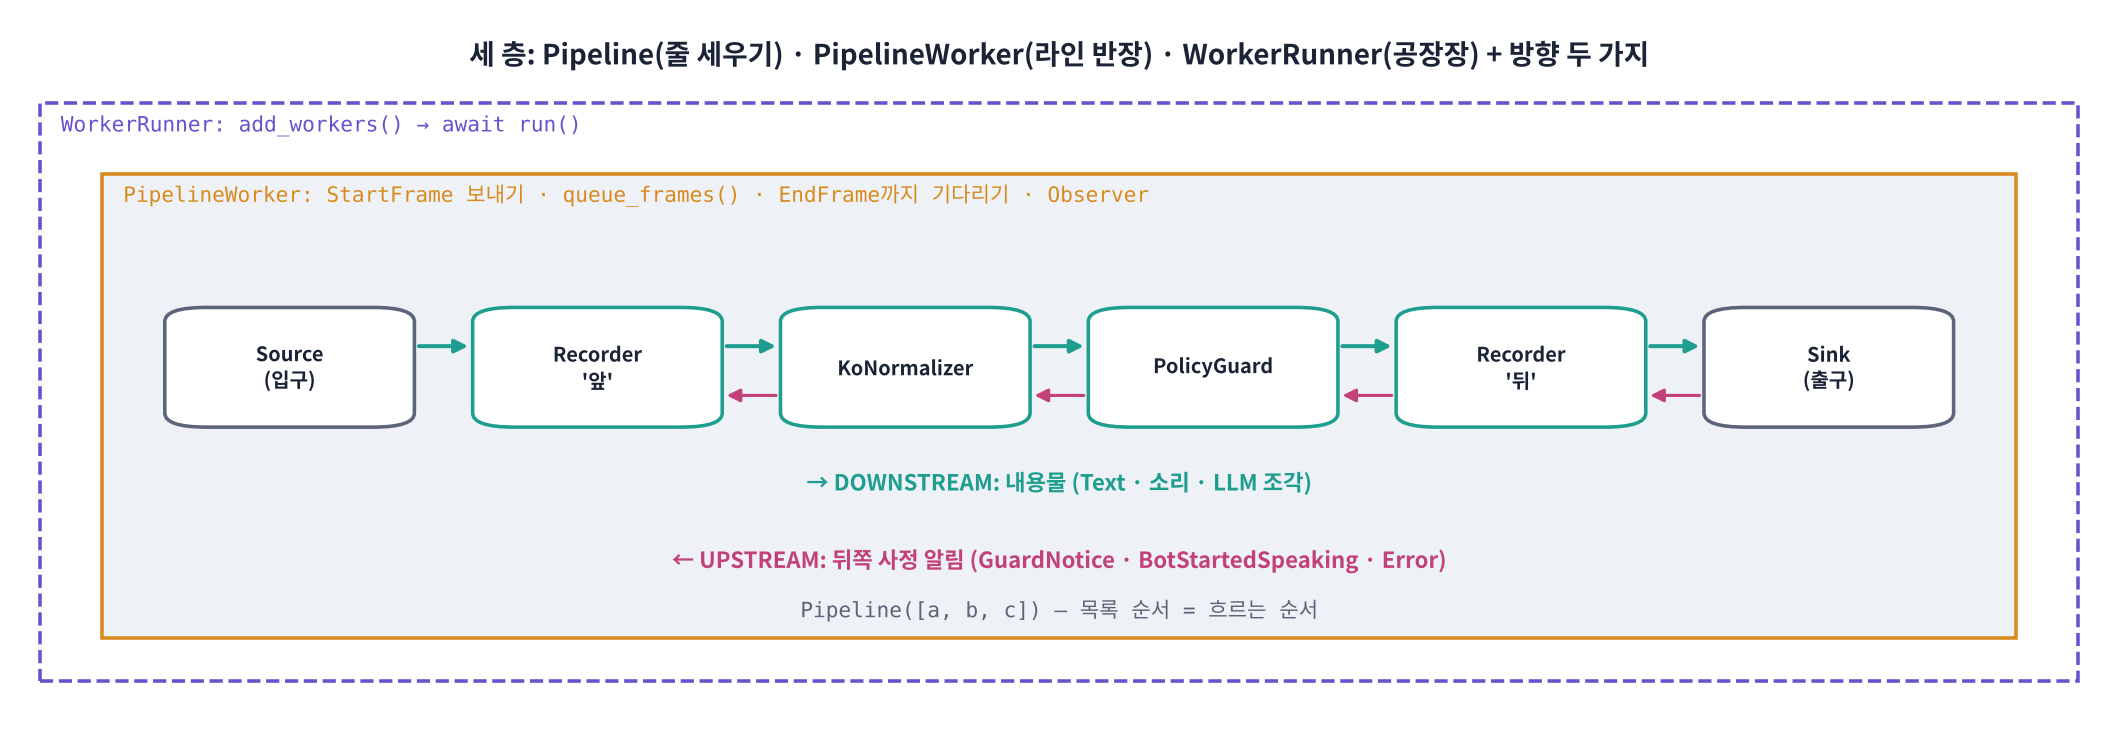

| 층 | 코드 | 하는 일 | 🍎 공장 비유 |
|---|---|---|---|
| **Pipeline** | `Pipeline([a, b, c])` | 작업자들을 **목록 순서대로** 줄 세움 (a의 출력이 b의 입력) | 컨베이어 라인 배치도 |
| **PipelineWorker** | `PipelineWorker(pipeline, params=...)` | 라인 하나를 **돌리는 단위**: StartFrame 보내기 · 상자 넣기(`queue_frames`) · 끝 처리 · 시간 초과 감시 | 라인 반장 |
| **WorkerRunner** | `runner.add_workers(w)` → `await runner.run()` | 여러 Worker를 띄우고 **모두 끝날 때까지** 기다렸다 정리 | 공장장 |

> ⚠️ 인터넷의 예제는 아직 옛 이름 `PipelineTask` · `PipelineRunner`를 많이 씁니다. 1.3.0부터 **`PipelineWorker` · `WorkerRunner`** 로 바뀌었고 옛 이름은 2.0에서 사라질 예정입니다(지금은 경고와 함께 동작).

**방향(direction)**: 상자는 보통 **앞 → 뒤(DOWNSTREAM)** 로 흐르지만, 뒤에서 앞으로 **거슬러(UPSTREAM)** 보낼 수도 있습니다. 실제로 Pipecat의 출력 Transport는 "봇이 말하기 시작했어요(`BotStartedSpeakingFrame`)"를 **앞쪽 작업자들에게** 거슬러 알립니다(Part 6에서 확인).

> 💬 **쉽게 말하면**: 내용물은 앞에서 뒤로, **"뒤쪽 사정" 알림은 뒤에서 앞으로** 흐릅니다.

> 🎬 **애니메이션 D27-4:** [방향: downstream · upstream](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#dir) — Guard가 상자를 막고 알림을 거슬러 보내는 모습

### 🧩 빈칸 실습 4: 거슬러 올라가는 알림
개인정보(주민번호)가 담긴 문장은 TTS로 읽으면 안 됩니다. `PolicyGuard`는 그런 TextFrame을 **버리고**, 앞쪽에 "막았다"는 알림 Frame을 **거슬러** 보냅니다. 알림 Frame은 `@dataclass`로 **직접 만든** SystemFrame입니다.

> ## 🎤 강사 스크립트 · Part 3 세 층 · 방향  ⏱️ 8분
>
> 🎯 **Pipeline = 순서, Worker = 실행 단위, Runner = 전체 관리. 알림은 거슬러 올라갈 수 있다.**
>
> 🖥️ 슬라이드 p.8 세 층 그림 → [D27-4 방향](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#dir).
>
> 🗣️ "예제에서 `PipelineTask`가 보이면 옛 이름입니다. 지금은 `PipelineWorker`. 이름만 바뀌었고 하는 일은 같습니다."
>
> ❓ "뒤에서 앞으로 알릴 일이 뭐가 있을까?" → 봇이 말하기 시작함(→ VAD가 끼어들기 감시), 오류, 개인정보 차단.

In [ ]:
# 🧩 빈칸 실습 4: 직접 만든 Frame을 upstream으로 보내기
@dataclass
class GuardNoticeFrame(SystemFrame):                     # 나만의 Frame: SystemFrame을 부모로 두고 필드 추가
    reason: str = ""

class PolicyGuard(FrameProcessor):
    BANNED = ["주민번호", "카드번호", "계좌번호"]
    async def process_frame(self, frame, direction):
        await super().process_frame(frame, direction)
        if isinstance(frame, TextFrame) and any(w in frame.text for w in self.BANNED):
            notice = GuardNoticeFrame(reason=f"개인정보 문장을 막음: {frame.text[:8]}…")
            await self.push_frame(notice, FrameDirection.____)                    # 빈칸 4: 뒤 → 앞 (거슬러)
            return                                       # 원래 TextFrame은 넘기지 않음 = 의도적으로 버림
        await self.push_frame(frame, direction)

front, back = Recorder("앞"), Recorder("뒤")
result = await run_frames([front, KoNormalizer(), PolicyGuard(), back],
                          [TextFrame(text="예약은 2시예요."), TextFrame(text="제 주민번호는 900101이에요."), TextFrame(text="감사합니다.")])
display(pd.concat([front.table(), back.table()]).sort_values("시각"))
notices = [r for r in front.rows if r["Frame"] == "GuardNoticeFrame"]
check(result["정상종료"] and len(notices) == 1 and notices[0]["방향"] == "UPSTREAM"
      and [r["내용"] for r in back.rows if r["Frame"] == "TextFrame"] == ["예약은 두 시예요.", "감사합니다."], hint="빈칸 4 = UPSTREAM")

> ## 🎤 강사 스크립트 · 🧩 빈칸 4  ⏱️ 7분
>
> 🆘 "뒤 → 앞, 거슬러" → `UPSTREAM`.
>
> ✅ 합친 표: '앞'에 GuardNoticeFrame(UPSTREAM, '개인정보 문장을 막음'), '뒤'에는 '예약은 두 시예요.' · '감사합니다.'만, ✅.
>
> ⚠️ 표의 시각 순서가 '앞'에서 GuardNotice가 EndFrame보다 늦게 보일 수 있음 → 거슬러 오는 길이 따로 있기 때문, 정상.
>
> 🗣️ "`return`으로 상자를 넘기지 않은 건 '깜빡'이 아니라 '의도적 버림'입니다. 차이는 StartFrame · EndFrame을 넘기느냐."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
await self.push_frame(notice, FrameDirection.UPSTREAM)   # 빈칸 4
```

**해설**: 기록표에서 GuardNoticeFrame은 **'앞' Recorder에만** 나타나고 방향이 `UPSTREAM`입니다. 뒤로는 가지 않았죠. 실제 비서라면 맨 앞의 작업자(예: LLM 쪽)가 이 알림을 받아 '그 정보는 전화로 말씀하지 마세요' 같은 안내를 하게 만들 수 있습니다. `return`으로 원래 상자를 넘기지 않은 것은 **의도적인 버림**입니다. Part 2의 '깜빡'과 달리 StartFrame · EndFrame은 그대로 넘기므로 파이프라인은 정상 종료됩니다.

</details>

### 🔭 Observer: 상자의 여행 기록
작업자 사이에 Recorder를 끼우지 않고도, **Observer**를 Worker에 달면 **모든 push(누가 → 누구에게, 언제, 어느 방향)** 를 볼 수 있습니다. 파이프라인 모양을 바꾸지 않는 '감시 카메라'입니다(D28의 지연 측정 Metrics도 이 방식).

In [ ]:
# 🔭 Observer: 파이프라인을 바꾸지 않고 모든 push를 기록
class FlowLog(BaseObserver):
    def __init__(self, first_only=False, **kwargs):
        super().__init__(**kwargs)
        self.first_only, self.rows = first_only, []      # first_only=True: 상자가 '처음 만들어져 나온' 순간만 기록
    async def on_push_frame(self, data: FramePushed):
        f = data.frame
        if isinstance(f, InputAudioRawFrame) or (self.first_only and not data.first_push):
            return
        self.rows.append(dict(t_ms=round(data.timestamp / 1e6, 2), 보낸쪽=data.source.name, 받는쪽=data.destination.name,
                              Frame=type(f).__name__, id=f.id, 방향=data.direction.name, 내용=getattr(f, "text", None)))
    def table(self):
        return pd.DataFrame(self.rows)

flow3 = FlowLog()
await run_frames([KoNormalizer(), PolicyGuard(), Recorder("끝")],
                 [TextFrame(text="예약은 2시예요."), TextFrame(text="제 주민번호는 900101이에요.")], observers=[flow3])
T3 = flow3.table()
print("① '예약은 2시예요.' 문장이 지나간 길 (KoNormalizer에서 새 상자로 바뀌며 내용이 달라짐):")
display(T3[T3["내용"].fillna("").str.startswith("예약은")][["t_ms", "보낸쪽", "받는쪽", "방향", "id", "내용"]])
print("② 알림 Frame이 지나간 길:")
display(T3[T3["Frame"] == "GuardNoticeFrame"][["t_ms", "보낸쪽", "받는쪽", "방향"]])
print(f"③ 전체 push {len(T3)}번 · Frame 종류별:", T3["Frame"].value_counts().to_dict())

> ## 🎤 강사 스크립트 · Observer  ⏱️ 7분
>
> ✅ ① 6줄: Source → KoNormalizer까지 id A · '2시', KoNormalizer 이후 id B · '두 시'. ② 3줄 UPSTREAM. ③ 전체 24번 내외.
>
> 🗣️ "Observer는 파이프라인 모양을 바꾸지 않는 감시 카메라입니다. 내일(D28) 지연 측정도 이 방식이에요."
>
> ❓ 생각해 보기(왜 push가 수십 번?) → 작업자 N명이면 N + 1번, 실제로는 20 ms마다 소리 조각까지.

👣 **표 읽기**: ①에서 문장은 `Pipeline#…::Source`(입구) → `KoNormalizer` → `PolicyGuard` → … → `::Sink`(출구) 순으로 지나갑니다. `KoNormalizer`가 **새 TextFrame을 만들어** 넘겼으므로 그 뒤로는 **id가 바뀌고 내용이 '두 시'** 입니다. ②의 알림은 `PolicyGuard`에서 출발해 **입구 쪽으로** 거슬러 갑니다.

**❓ 생각해 보기**: TextFrame 2개만 넣었는데 push가 수십 번입니다. 무엇이 이렇게 많이 지나갔을까요?

<details>
<summary>답 보기</summary>

③의 종류별 개수를 보면 **StartFrame · EndFrame** 같은 수명 신호와, Pipecat이 시작할 때 스스로 주고받는 설정 Frame(`...MetadataFrame` 등)이 섞여 있습니다. 상자 하나가 작업자 N명을 지나면 push가 N + 1번 일어납니다. 실제 음성 비서에서는 20 ms마다 소리 조각까지 흐르므로 1초에 수백 번의 push가 일어나고, 그래서 **각 작업자의 `process_frame`은 빨리 끝나야** 합니다(Part 4의 '루프 막힘' 실험).

</details>

> 📝 **워크시트 2교시** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day27/worksheet.html) — Pipeline · 방향 · Observer 10문항

> ## 🎤 강사 스크립트 · 워크시트 2교시  ⏱️ 8분
>
> 🖥️ [worksheet.html 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day27/worksheet.html) 10문항.

## Part 4. 서비스: STT · TTS · LLM도 결국 FrameProcessor

Pipecat의 **서비스(Service)** 는 AI 모델을 감싼 특별한 FrameProcessor입니다. 모델 부르는 함수 하나만 채우면, 나머지(StartFrame 처리 · 끼어들기 · 문장 모으기 · 시간 재기)는 부모 클래스가 해 줍니다.

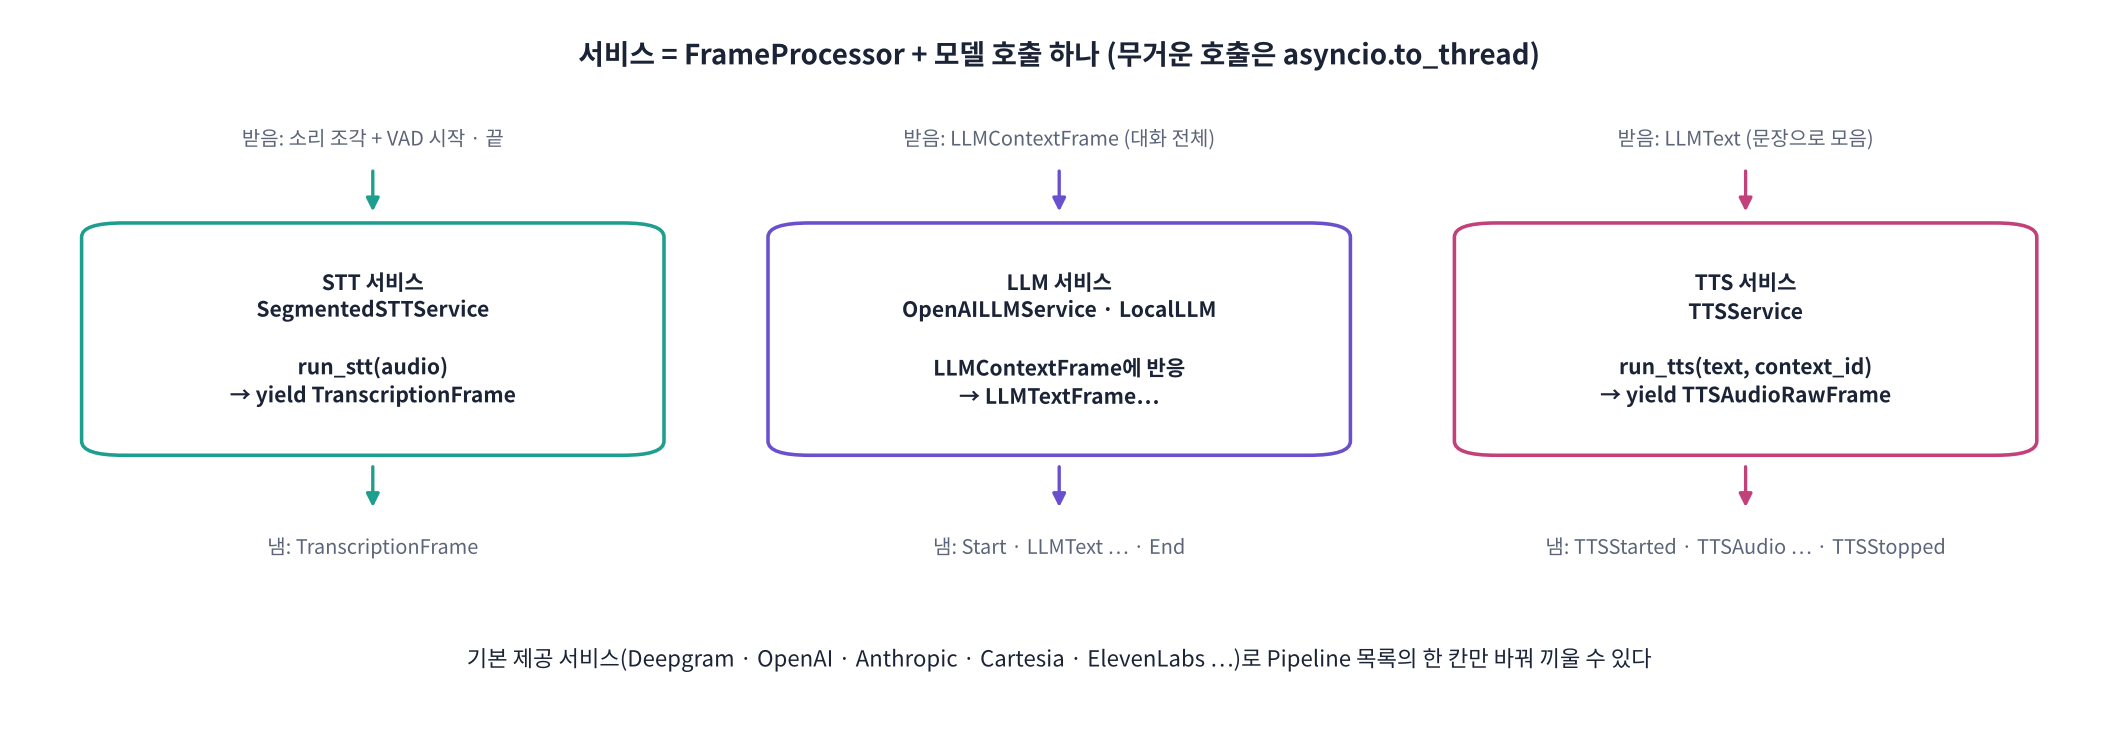

| 서비스 | 받는 Frame | 내보내는 Frame | 내가 채우는 곳 | 기본 제공 예 (한 줄로 교체) |
|---|---|---|---|---|
| **STT** (`SegmentedSTTService`) | 소리 조각 + VAD 말 시작 · 끝 | `TranscriptionFrame` | `run_stt(audio)` | Deepgram · OpenAI · Google · AssemblyAI · Whisper(faster-whisper) |
| **LLM** | `LLMContextFrame` (대화 전체) | `LLMTextFrame`들 (+ 시작 · 끝 표시) | (직접 만들면) `process_frame` | OpenAI · Anthropic · Google · Groq · Ollama |
| **TTS** (`TTSService`) | `TextFrame`(LLM 조각을 **문장 단위로 모아서**) | `TTSAudioRawFrame`들 | `run_tts(text, context_id)` | Cartesia · ElevenLabs · Kokoro · Piper · OpenAI |

> 💬 **쉽게 말하면**: 오늘 우리 모델(Whisper · Edge TTS · Qwen3)을 서비스로 감싸 두면, 나중에 상용 서비스로 **Pipeline 목록의 한 칸만 바꿔** 끼울 수 있습니다.

> 📐 **핵심 식 하나**: **서비스 = FrameProcessor + 모델 호출 하나**. 모델 호출은 `await asyncio.to_thread(...)`로 **다른 스레드에서** 돌립니다(아래 실험).

> 🎬 **애니메이션 D27-5:** [서비스 세 개](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#svc) — 각 서비스가 무엇을 받아 무엇을 내보내는지, 문장 모으기
> 🎬 **애니메이션 D27-6:** [이벤트 루프 막힘](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#loop) — 무거운 모델을 그냥 부르면 20 ms 박동이 끊기는 모습

### 🧩 빈칸 실습 5: Whisper STT 서비스
`SegmentedSTTService`는 VAD가 **말 시작 ~ 끝** 구간의 소리를 모아 `run_stt()`에 한 번에 넘겨 줍니다(D8의 청크 방식). 받아쓴 글자를 어떤 Frame에 담아 내보낼까요? (Part 1 표 참고)

> ## 🎤 강사 스크립트 · Part 4 서비스  ⏱️ 6분
>
> 🎯 **서비스 = 작업자 + 모델 호출 하나. 모델 호출은 스레드로.**
>
> 🖥️ [D27-5 서비스 세 개](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#svc): LLM 조각이 TTS 앞에서 문장으로 모이는 장면.
>
> 🗣️ "Deepgram, ElevenLabs 같은 상용 서비스도 똑같은 모양입니다. 오늘 우리 모델로 감싸 두면 나중에 한 칸만 바꿔 끼웁니다."

In [ ]:
# 🧩 빈칸 실습 5: 우리 Whisper를 Pipecat STT 서비스로 감싸기
from pipecat.services.stt_service import SegmentedSTTService
from pipecat.services.tts_service import TTSService
from pipecat.services.settings import STTSettings, TTSSettings
from pipecat.processors.audio.vad_processor import VADProcessor
from pipecat.audio.vad.silero import SileroVADAnalyzer
from pipecat.transcriptions.language import Language
from pipecat.utils.time import time_now_iso8601

class WhisperSTT(SegmentedSTTService):
    # VAD가 '말 끝'을 알리면 그 구간 소리를 통째로 받아 Whisper로 받아쓰는 STT 서비스
    def __init__(self, **kwargs):
        super().__init__(settings=STTSettings(model=ASR_NAME, language=Language.KO), ttfs_p99_latency=1.0, **kwargs)
    @property
    def wants_wav_segments(self):
        return False                                     # WAV 머리말 없이 int16 PCM 바이트로 받기
    async def run_stt(self, audio: bytes):
        y = np.frombuffer(audio, np.int16).astype(np.float32) / 32768
        text = await asyncio.to_thread(stt, y)           # 무거운 모델은 다른 스레드에서
        yield ____(text=text, user_id="", timestamp=time_now_iso8601())                 # 빈칸 5

rec = Recorder("STT 뒤")
result = await run_frames([VADProcessor(vad_analyzer=SileroVADAnalyzer()), WhisperSTT(), rec],
                          feed=mic(VOICE1, wait=(rec, TranscriptionFrame)))
T = rec.table()
display(T[T["Frame"].isin(["VADUserStartedSpeakingFrame", "VADUserStoppedSpeakingFrame", "TranscriptionFrame"])])
t_stop = T[T["Frame"] == "VADUserStoppedSpeakingFrame"]["시각"].max()
t_text = T[T["Frame"] == "TranscriptionFrame"]["시각"].min()
STT_SEC = round(t_text - t_stop, 2) if t_text == t_text else None
print(f"VAD '말 끝' → 받아쓰기 도착: {STT_SEC}초")
check(result["정상종료"] and (T["Frame"] == "TranscriptionFrame").any(), hint="빈칸 5 = TranscriptionFrame")

> ## 🎤 강사 스크립트 · 🧩 빈칸 5 STT  ⏱️ 8분
>
> 🆘 "받아쓴 글자 = Trans___ Frame" → `TranscriptionFrame`.
>
> ✅ (약 5초 실행) 표 3줄: VADUserStarted(약 0.8초) → VADUserStopped(약 3초) → TranscriptionFrame(받아쓴 문장). `VAD '말 끝' → 받아쓰기 도착: 0.3 ~ 0.6초`(T4 whisper-small), ✅.
>
> ⚠️ `yield` 대신 `return`이면 SyntaxError('return with value in async generator').

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
yield TranscriptionFrame(text=text, user_id="", timestamp=time_now_iso8601())   # 빈칸 5
```

**해설**: `run_stt`는 `return`이 아니라 **`yield`** 로 Frame을 내보내는 **비동기 제너레이터**입니다. 부모 클래스가 yield된 Frame을 받아 `push_frame`해 줍니다. 그래서 한 번에 여러 Frame(예: 중간 결과 `InterimTranscriptionFrame` 여러 개 + 최종 결과)을 낼 수 있습니다. `user_id`는 여러 사람이 있는 방(D29 LiveKit)에서 '누구의 말'인지 구분할 때 씁니다. 기록표에서 VAD 말 시작 · 끝(System)이 먼저 지나가고, 말 끝 **뒤에** 받아쓰기가 도착하는 것을 확인하세요. 그 사이 시간이 STT가 쓴 시간입니다.

</details>

### 🧩 빈칸 실습 6: 한국어 TTS 서비스와 `asyncio.to_thread`
Pipecat은 **한 스레드의 이벤트 루프**에서 모든 작업자를 번갈아 돌립니다. 모델을 그냥 부르면 그동안 **루프 전체가 멈춰** 소리 조각 · VAD · 다른 작업자가 모두 기다립니다. 무거운 함수를 **다른 스레드에서** 돌리고 결과를 `await`로 기다리는 함수는 `asyncio.____`.

In [ ]:
# 🧩 빈칸 실습 6: 우리 tts()(Edge 신경망 음성, 예비 MMS-TTS)를 Pipecat TTS 서비스로 감싸기
class KoTTS(TTSService):
    # 문장(TextFrame)을 받아 tts()로 합성해 TTSAudioRawFrame으로 내보내는 TTS 서비스
    def __init__(self, **kwargs):
        super().__init__(sample_rate=SR, push_start_frame=True, push_stop_frames=True,
                         settings=TTSSettings(model="edge-tts", voice=VOICE_BOT, language=None), **kwargs)
    async def run_tts(self, text: str, context_id: str):
        y = await asyncio.____(tts, normalize_ko(text))                              # 빈칸 6: 다른 스레드에서 합성
        pcm = (np.clip(y, -1, 1) * 32767).astype(np.int16).tobytes()
        yield TTSAudioRawFrame(audio=pcm, sample_rate=SR, num_channels=1, context_id=context_id)

rec = Recorder("TTS 뒤")
result = await run_frames([KoTTS(), rec], [TTSSpeakFrame(text="네, 다음 주 수요일 오후 2시로 예약해 드릴게요.")])
T = rec.table()
display(T[~T["Frame"].isin(["TTSAudioRawFrame"])].head(12))
play(rec.sound(), SR, "TTS 서비스가 만든 소리 ('두 시'로 읽는지 들어 보기)")
check(result["정상종료"] and len(rec.sound()) > SR * 0.5 and {"TTSStartedFrame", "TTSStoppedFrame"} <= set(T["Frame"]),
      hint="빈칸 6 = to_thread")

> ## 🎤 강사 스크립트 · 🧩 빈칸 6 TTS  ⏱️ 6분
>
> 🆘 "다른 스레드로 → to ___" → `to_thread`.
>
> ✅ 표: StartFrame → AggregatedTextFrame → TTSStartedFrame → TTSTextFrame → TTSStoppedFrame → EndFrame, 🎧 '오후 **두 시**로', ✅.
>
> 🎧 반 전체가 듣기: "이 시"가 아니라 "두 시"로 읽는지.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
y = await asyncio.to_thread(tts, normalize_ko(text))   # 빈칸 6
```

**해설**: `asyncio.to_thread(함수, 인자...)`는 함수를 **별도 스레드**에서 실행하고, 그동안 이벤트 루프는 다른 작업자(VAD · 소리 전송 등)를 계속 돌립니다. PyTorch는 계산 중 GIL을 풀어 주므로 스레드로도 효과가 있습니다. `TTSSpeakFrame`은 'LLM 없이 이 문장을 그대로 말해'라는 Frame으로, 인사말이나 고정 안내에 씁니다. `push_start_frame · push_stop_frames=True`라서 소리 앞뒤로 `TTSStartedFrame` · `TTSStoppedFrame`(Control)이 붙었습니다. 숫자 정규화를 Part 2처럼 **별도 작업자**가 아니라 `run_tts` 안에서 한 이유는 아래 ❓를 보세요.

</details>

In [ ]:
# 🧪 실험: 이벤트 루프를 막으면? 20 ms마다 뛰어야 할 '심장 박동'이 얼마나 늦어지나
async def heartbeat(stop, gaps):
    last = time.perf_counter()
    while not stop.is_set():
        await asyncio.sleep(0.02)
        now = time.perf_counter(); gaps.append((now - last) * 1000); last = now

async def measure(job):
    stop, gaps = asyncio.Event(), []
    hb = asyncio.ensure_future(heartbeat(stop, gaps))
    await asyncio.sleep(0.2)
    t = time.perf_counter(); await job(); sec = time.perf_counter() - t
    await asyncio.sleep(0.1); stop.set(); await hb
    return dict(걸린시간_초=round(sec, 2), 박동_최대간격_ms=round(max(gaps), 1), 늦은박동_40ms초과=sum(g > 40 for g in gaps))

LONG = "안녕하세요 한빛치과입니다 오늘 진료는 오후 여섯 시까지이고 점심시간은 한 시부터 두 시까지입니다"
async def blocking():                                    # ❌ 루프 위에서 그냥 호출
    tts(LONG); stt(VOICE1)
async def threaded():                                    # ✅ 다른 스레드에서
    await asyncio.to_thread(tts, LONG); await asyncio.to_thread(stt, VOICE1)
LOOP = pd.DataFrame([dict(방식="그냥 호출", **await measure(blocking)), dict(방식="asyncio.to_thread", **await measure(threaded))])
display(LOOP)
print("→ '그냥 호출'의 최대 간격 동안 마이크 조각 · VAD · 소리 전송이 모두 멈춰 있었다는 뜻")

> ## 🎤 강사 스크립트 · 🧪 루프 막힘 실험  ⏱️ 6분
>
> 🖥️ [D27-6 이벤트 루프 막힘](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#loop) 먼저 보여 주고 실행.
>
> ✅ 예상(T4): 그냥 호출 → 최대 간격 수백 ms(합성 + 받아쓰기 시간만큼), to_thread → 20 ~ 30 ms.
>
> 🗣️ "최대 간격 수백 ms 동안 마이크 조각 수십 개가 처리되지 못하고 쌓였다는 뜻입니다. 어제 배운 말로 하면, 내 서버 안에서 지터를 만든 것이죠."
>
> ❓ 생각해 보기(정규화 위치) → 토큰 조각 vs 문장. "어떤 단위의 Frame을 다루는지가 작업자 위치를 정한다."

**❓ 생각해 보기**: Part 2의 KoNormalizer를 LLM 바로 뒤(TTS 앞)에 작업자로 끼우면 될 것 같은데, 왜 run_tts 안에서 정규화했을까요?

<details>
<summary>답 보기</summary>

LLM은 글자를 **토큰 조각**으로 냅니다. '2시'가 `LLMTextFrame('1')` · `LLMTextFrame('2시')`처럼 쪼개져 오면 조각마다 정규화해서는 '12시'를 알아볼 수 없습니다(게다가 KoNormalizer는 `type(frame) is TextFrame`만 바꾸므로 LLMTextFrame은 그냥 지나감). TTS 서비스는 조각들을 **문장 단위로 모은 뒤** `run_tts(text)`를 부르므로, 그 안에서 정규화하면 '오후 12시' 전체를 보고 '열두 시'로 바꿀 수 있습니다. **어느 단위(조각 · 문장 · 턴)의 Frame을 다루는지**가 작업자 위치를 정합니다.

</details>

### 🧩 빈칸 실습 7: LLM 서비스
LLM 서비스는 **대화 전체(`LLMContext`)를 담은 Frame**을 받으면 답을 만들기 시작합니다. 클라우드 LLM은 Pipecat의 `OpenAILLMService`를 쓰고(세 회사 모두 OpenAI 호환 주소가 있어 `base_url`만 바꿈), 로컬 Qwen3는 직접 만든 `LocalLLM`으로 감쌉니다. `LocalLLM`이 반응해야 하는 Frame은?

In [ ]:
# 🧩 빈칸 실습 7: LLM 서비스 (클라우드 = OpenAILLMService, 로컬 = 직접 만든 LocalLLM)
from pipecat.processors.aggregators.llm_context import LLMContext
from pipecat.services.openai.llm import OpenAILLMService
from threading import Thread
from transformers import TextIteratorStreamer

class LocalLLM(FrameProcessor):
    # 대화 전체(LLMContextFrame)를 받아 → 답을 조각조각 LLMTextFrame으로 내보내는 '직접 만든 LLM 서비스'
    def __init__(self, generate, system_instruction="", **kwargs):
        super().__init__(**kwargs)
        self.generate = generate                         # generate(messages) → 글자 조각을 하나씩 내는 iterator
        self.system = [{"role": "system", "content": system_instruction}] if system_instruction else []
    async def process_frame(self, frame, direction):
        await super().process_frame(frame, direction)
        if isinstance(frame, ____):                                                  # 빈칸 7
            await self.push_frame(LLMFullResponseStartFrame())
            it = self.generate(self.system + frame.context.get_messages())
            while (piece := await asyncio.to_thread(next, it, None)) is not None:
                if piece: await self.push_frame(LLMTextFrame(text=piece))
            await self.push_frame(LLMFullResponseEndFrame())
        else:
            await self.push_frame(frame, direction)

def qwen_stream(messages):                               # D22의 stream_local과 같음
    text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    enc = tok(text, return_tensors="pt").to(DEVICE)
    streamer = TextIteratorStreamer(tok, skip_prompt=True, skip_special_tokens=True)
    Thread(target=llm_model.generate, kwargs=dict(**enc, max_new_tokens=80, do_sample=False, repetition_penalty=1.1, streamer=streamer)).start()
    return iter(streamer)

def make_llm():
    if PROVIDER == "local":
        return LocalLLM(qwen_stream, system_instruction=SYSTEM)
    return OpenAILLMService(api_key=secret(KEYS[PROVIDER]), base_url=BASE_URLS[PROVIDER],
                            settings=OpenAILLMService.Settings(model=MODELS[PROVIDER], system_instruction=SYSTEM))

# ① 빈칸 확인: 가짜 생성기로 LocalLLM이 Frame을 제대로 내는지
rec = Recorder("LLM 뒤")
ctx = LLMContext([{"role": "user", "content": SAY1}])
await run_frames([LocalLLM(lambda msgs: iter(["네, ", "수요일 ", "오후 2시 ", "말씀이시죠?"])), rec], [LLMContextFrame(context=ctx)])
fake = [r["Frame"] for r in rec.rows if r["Frame"].startswith("LLM")]
# ② 진짜 LLM으로: 첫 글자까지 시간(TTFT)과 답
rec2 = Recorder("LLM 뒤")
await run_frames([make_llm(), rec2], [LLMContextFrame(context=LLMContext([{"role": "user", "content": SAY1}]))], timeout=90)
T = rec2.table(); toks = T[T["Frame"] == "LLMTextFrame"]
LLM_TTFT = round(toks["시각"].min() - T[T["Frame"] == "LLMFullResponseStartFrame"]["시각"].min(), 2) if len(toks) else None
print(f"{PROVIDER} · 조각 {len(toks)}개 · 시작 → 첫 글자 {LLM_TTFT}초\n답: {''.join(toks['내용'])}")
check(fake == ["LLMFullResponseStartFrame"] + ["LLMTextFrame"] * 4 + ["LLMFullResponseEndFrame"], hint="빈칸 7 = LLMContextFrame")

> ## 🎤 강사 스크립트 · 🧩 빈칸 7 LLM  ⏱️ 10분
>
> 🆘 "LLM에게 '대화 전체를 보고 답해' = LLM___Frame" → `LLMContextFrame`.
>
> ✅ 출력 `{PROVIDER} · 조각 N개 · 시작 → 첫 글자 X초` + 답 문장, ✅. 클라우드면 첫 글자 0.3 ~ 1초, 로컬 Qwen(T4)이면 0.2 ~ 0.5초 + 생성 시간.
>
> ⚠️ 클라우드에서 `Connection error`·401 → 키 · 모델 이름 확인. 수업 중에는 `PROVIDER = "local"`로 넘어가고 쉬는 시간에 해결.
>
> 🗣️ "`OpenAILLMService`도 속에서는 지금 만든 LocalLLM과 똑같이 Start → 조각들 → End를 냅니다."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
if isinstance(frame, LLMContextFrame):   # 빈칸 7
```

**해설**: Pipecat의 LLM 서비스는 **'답해 주세요' = `LLMContextFrame`** 을 받을 때만 일합니다. 이 Frame에는 지금까지의 대화 · 도구 목록이 담긴 `LLMContext`가 들어 있습니다(D22 대화 이력, D23 도구). 시스템 프롬프트는 Pipecat 1.9부터 **LLM 서비스 쪽(`system_instruction`)** 에 두는 것이 권장 방식이라, 대화 기록과 따로 관리됩니다. 답은 `LLMFullResponseStartFrame` → `LLMTextFrame` 여러 개 → `LLMFullResponseEndFrame`으로 감싸서 내보내는 것이 약속이고, 뒤의 TTS · Context Aggregator가 이 표시를 보고 '한 답의 시작과 끝'을 압니다. `OpenAILLMService`도 속에서는 똑같이 동작합니다. `next(it, None)`을 `to_thread`로 부른 것은 **토큰 하나를 기다리는 동안에도 루프를 막지 않기** 위해서입니다.

</details>

> 📝 **워크시트 3교시** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day27/worksheet.html) — 서비스 · 이벤트 루프 10문항

> ## 🎤 강사 스크립트 · 워크시트 3교시  ⏱️ 6분
>
> 🖥️ [worksheet.html 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day27/worksheet.html) 10문항.

## Part 5. 조립: VAD → STT → 사용자 턴 → LLM → TTS → 대화 기록

서비스 세 개를 이으려면 **두 가지 접착제**가 더 필요합니다.

| 작업자 | 위치 | 하는 일 |
|---|---|---|
| **사용자 쪽 Aggregator** (`user_agg`) | STT 뒤 · LLM 앞 | 받아쓴 글자를 모으다가 **"사용자 턴이 끝났다"** 고 판단하면 → 대화 기록에 `user` 메시지를 넣고 → `LLMContextFrame`을 LLM에 보냄 |
| **봇 쪽 Aggregator** (`assistant_agg`) | **맨 끝** (출력 뒤) | LLM이 낸 조각들을 모아 → 답이 끝나면(`LLMFullResponseEndFrame`) 대화 기록에 `assistant` 메시지를 넣음 |

두 Aggregator는 **같은 `LLMContext`** 를 나눠 씁니다. 그래서 D22에서 손으로 하던 `messages.append(...)`가 저절로 됩니다.

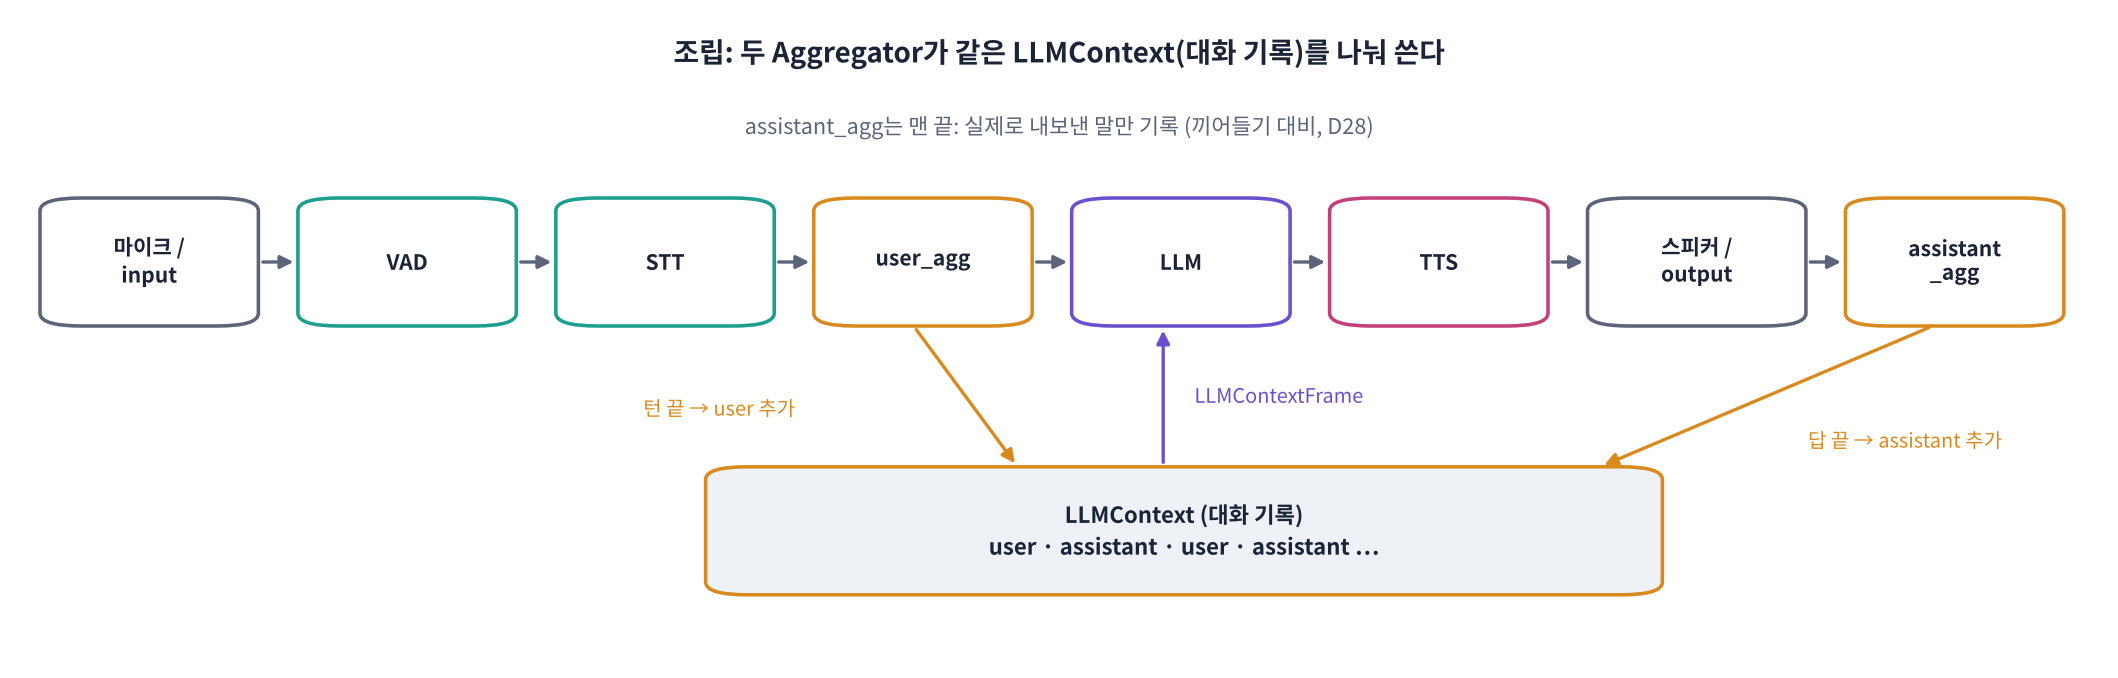

> 💬 **쉽게 말하면**: user_agg는 **"손님 말 다 끝났어요, 답하세요!"** 라고 알리는 사람, assistant_agg는 **"방금 비서가 한 말"을 장부에 적는 사람**입니다.

> 🍎 **비유: 전화 상담 기록지.** 상담원(LLM)은 기록지 전체를 보고 답하고, 손님 말이 끝나면 한 줄, 상담원 답이 끝나면 한 줄 적습니다.

👣 **한 단계씩: 한 턴에 일어나는 일**
1. VAD: `VADUserStartedSpeakingFrame` … `VADUserStoppedSpeakingFrame` (말소리 구간)
2. STT: 말 끝 뒤 `TranscriptionFrame`
3. user_agg: 말 끝 뒤 **0.6초** 더 조용하면(`SpeechTimeoutUserTurnStopStrategy`) 턴 끝 → `UserStoppedSpeakingFrame` + `LLMContextFrame`
4. LLM: `LLMFullResponseStartFrame` → `LLMTextFrame`들 → `LLMFullResponseEndFrame`
5. TTS: 문장이 모이면 `TTSAudioRawFrame`들 → 스피커
6. assistant_agg: 답을 기록에 추가 → 다음 턴의 LLM이 이 기록을 봄

> 📐 **핵심 식 하나**: **응답 시간 ≈ 턴 끝 대기(0.6초) + STT + LLM 첫 문장 + TTS 첫 문장**. 턴 끝을 판단하는 똑똑한 방법(Smart Turn)과 끼어들기는 **D28**에서 다룹니다.

> 🎬 **애니메이션 D27-7:** [조립된 파이프라인](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#assemble) — 한 턴 동안 Frame들이 어떤 순서로 흐르는지 재생

### 🧩 빈칸 실습 8: 파이프라인 목록 완성
`assistant_agg`는 **봇이 실제로 내보낸 것**을 기록해야 하므로 목록의 어디에 두어야 할까요?

> ## 🎤 강사 스크립트 · Part 5 조립  ⏱️ 6분
>
> 🎯 **두 Aggregator가 같은 기록지를 나눠 쓴다. assistant_agg는 맨 끝.**
>
> 🖥️ [D27-7 조립된 파이프라인](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#assemble): 한 턴 재생 버튼.
>
> 🍎 전화 상담 기록지: "손님 말 끝나면 한 줄, 상담원 답 끝나면 한 줄."

In [ ]:
# 🧩 빈칸 실습 8: 두 턴 대화 파이프라인
from pipecat.processors.aggregators.llm_response_universal import LLMContextAggregatorPair, LLMUserAggregatorParams
from pipecat.turns.user_turn_strategies import UserTurnStrategies
from pipecat.turns.user_stop.speech_timeout_user_turn_stop_strategy import SpeechTimeoutUserTurnStopStrategy

TURN_WAIT = 0.6                                          # ✏️ 말 끝 뒤 몇 초 조용하면 '턴 끝'으로 볼까 (0.3 · 0.6 · 1.0)
def make_bot():
    context = LLMContext()                               # 대화 기록 (시스템 프롬프트는 LLM 서비스의 system_instruction에)
    user_agg, assistant_agg = LLMContextAggregatorPair(context, user_params=LLMUserAggregatorParams(
        user_turn_strategies=UserTurnStrategies(stop=[SpeechTimeoutUserTurnStopStrategy(user_speech_timeout=TURN_WAIT)])))
    return context, user_agg, assistant_agg

context, user_agg, assistant_agg = make_bot()
speaker = Recorder("스피커")                              # 스피커(출력 Transport) 자리: 나온 소리를 모음
flow5 = FlowLog(first_only=True)
parts = [VADProcessor(vad_analyzer=SileroVADAnalyzer()), WhisperSTT(), user_agg, make_llm(), KoTTS(), speaker, ____]   # 빈칸 8
result = await run_frames(parts, feed=mic(VOICE1, VOICE2, wait=(speaker, LLMFullResponseEndFrame)), observers=[flow5], timeout=180)
print(result)
HIST = pd.DataFrame(context.get_messages())[["role", "content"]]
display(HIST)
for k in range(len(speaker.marks)):
    play(speaker.sound(k), SR, f"비서 답 {k + 1}")
check(result["정상종료"] and list(HIST["role"]) == ["user", "assistant", "user", "assistant"], hint="빈칸 8 = assistant_agg (맨 끝)")

> ## 🎤 강사 스크립트 · 🧩 빈칸 8 두 턴 대화  ⏱️ 10분
>
> 🆘 "출력 뒤, 맨 끝에 서는 기록 담당" → `assistant_agg`.
>
> ✅ (약 15 ~ 30초) 대화 기록 4줄: user(예약 요청) → assistant(이름 묻기 등) → user(김민준) → assistant(확인), 🎧 비서 답 1 · 2, ✅.
>
> 🎧 두 번째 답이 첫 턴 내용(수요일 · 두 시 · 스케일링)을 기억하는지 같이 들어 보기.
>
> ⚠️ 로컬 Qwen 0.6B(CPU)는 엉뚱한 답이 나올 수 있음 → '구조가 돌아간다'에 집중.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
parts = [VADProcessor(...), WhisperSTT(), user_agg, make_llm(), KoTTS(), speaker, assistant_agg]   # 빈칸 8
```

**해설**: `assistant_agg`는 **출력(스피커 · Transport) 뒤 맨 끝**에 둡니다. 끼어들기(D28)로 답이 중간에 끊기면 **실제로 사용자에게 전달된 부분까지만** 기록해야 다음 턴의 LLM이 '내가 어디까지 말했는지' 정확히 알기 때문입니다. 기록표를 보면 두 번째 `user` 메시지 전에 첫 번째 `assistant` 답이 들어 있어서, 비서가 두 번째 말('이름은 김민준')을 **첫 턴의 맥락(수요일 2시 스케일링)과 이어서** 이해할 수 있습니다. D22에서 손으로 하던 대화 이력 관리를 두 Aggregator가 대신한 것입니다.

</details>

In [ ]:
# ⏱️ 턴마다 걸린 시간: Observer 기록에서 '말 끝(VAD)'을 0초로 맞춰 보기 (D28에서 Metrics로 정식 측정)
F5 = flow5.table()
F5["t"] = F5["t_ms"] / 1000
rows = []
for k, t_turn in enumerate(F5[(F5["Frame"] == "UserStoppedSpeakingFrame") & (F5["방향"] == "DOWNSTREAM")]["t"]):
    before, after = F5[F5["t"] <= t_turn], F5[F5["t"] >= t_turn]
    t0 = before[before["Frame"] == "VADUserStoppedSpeakingFrame"]["t"].max()          # 이 턴의 마지막 '말 끝'
    first = lambda name, df=after: df[df["Frame"] == name]["t"].min()
    stt_t = before[(before["Frame"] == "TranscriptionFrame") & (before["t"] >= t0 - 0.01)]["t"].min()
    rows.append(dict(턴=k + 1, 받아쓰기=stt_t - t0, 턴끝판정=t_turn - t0, LLM첫글자=first("LLMTextFrame") - t0, 첫소리=first("TTSAudioRawFrame") - t0))
TURNS = pd.DataFrame(rows).round(2)
display(TURNS)
fig, ax = plt.subplots(figsize=(9, 2.2 + 0.5 * len(TURNS)))
cols = [("받아쓰기", "#1E9E8F"), ("턴끝판정", "#D98A1E"), ("LLM첫글자", "#6A4FCF"), ("첫소리", "#C2417A")]
for i, r in TURNS.iterrows():
    for name, col in cols:
        ax.scatter(r[name], i, color=col, s=70, zorder=3, label=name if i == 0 else None)
    ax.hlines(i, 0, r["첫소리"], color="#D6DCE6", lw=6, zorder=1)
ax.axvline(0, color="#1B2336", ls="--"); ax.set_yticks(range(len(TURNS))); ax.set_yticklabels([f"turn {t}" for t in TURNS["턴"]])
ax.set_xlabel("seconds after user stopped speaking (VAD)"); ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

> ## 🎤 강사 스크립트 · 턴별 시간  ⏱️ 5분
>
> ✅ 표 2줄 + 점 그래프. 예상(T4 · 클라우드): 받아쓰기 0.3 ~ 0.6 · 턴끝판정 약 0.6 · LLM첫글자 1.0 ~ 1.5 · 첫소리 1.2 ~ 2.0초.
>
> ❓ TURN_WAIT 0.3으로 → 빨라지지만 말 중간 숨 고르기에서 잘림. "D28 Smart Turn이 이 문제를 풉니다."

👣 **표 읽기**: 턴 끝 판정은 **'0.6초 조용함'과 '받아쓰기 도착' 중 늦은 쪽**에 납니다(받아쓰기 없이 턴을 끝내지 않음). T4에서 받아쓰기가 0.6초 안에 끝나면 **조용함을 기다리는 시간이 가장 큰 덩어리**가 되고, CPU처럼 STT가 느리면 STT가 병목이 됩니다. LLM 첫 글자에서 첫 소리까지는 TTS가 **첫 문장이 모일 때까지** 기다린 시간입니다.

**❓ 생각해 보기**: TURN_WAIT를 0.3초로 줄이면 응답은 빨라집니다. 무엇이 나빠질까요? 실제로 바꿔서 두 턴을 다시 돌려 보세요.

<details>
<summary>답 보기</summary>

사람은 말하다가 0.3 ~ 0.5초쯤 **숨을 고르거나 생각하며 멈춥니다**('다음 주 수요일… 오후 두 시에'). 기다림이 짧으면 그 사이에 턴이 끝났다고 보고 **말을 자르고 답을 시작**합니다. 반대로 1초 이상이면 매 턴 1초씩 어색한 침묵이 생깁니다. 그래서 실제 서비스는 '조용한 시간'만 보지 않고, 말의 내용 · 억양으로 끝을 판단하는 **Smart Turn 모델**을 함께 씁니다(D28).

</details>

## Part 6. Transport 바꿔 끼우기: 같은 비서를 WebSocket으로

지금까지는 `mic()`가 소리를 넣고 `Recorder("스피커")`가 소리를 받았습니다. 실제 서비스에서는 이 자리에 **Transport**가 들어갑니다. Transport는 **바깥 세상(브라우저 · 전화 · 앱)과 파이프라인을 잇는 문** 이고, `transport.input()`과 `transport.output()` 두 작업자를 줍니다.

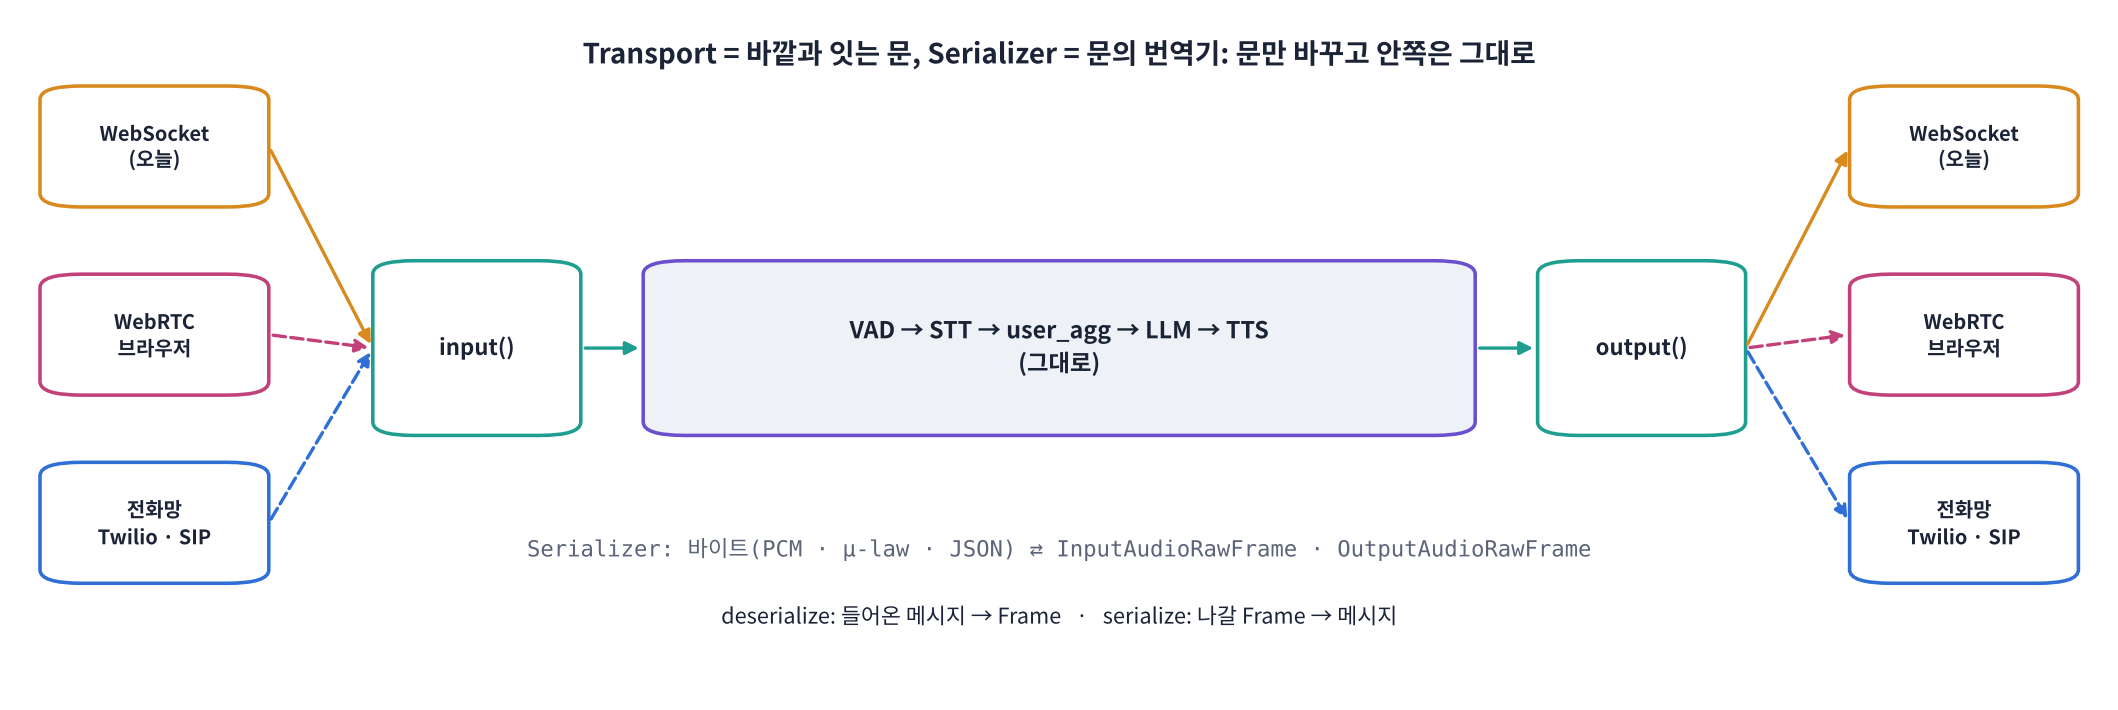

| Transport | 바깥 세상 | 언제 |
|---|---|---|
| `SingleClientWebsocketServerTransport` | WebSocket 클라이언트 (오늘) | 서버끼리 · 간단한 앱 · 실습 |
| `FastAPIWebsocketTransport` + Twilio · Telnyx 등 Serializer | 전화망 (μ-law 8 kHz, D26) | 전화 상담 (D30 SIP) |
| `SmallWebRTCTransport` | 브라우저 (WebRTC 직접 연결) | 1:1 웹 데모 (D32) |
| `DailyTransport` · `LiveKitTransport` | WebRTC 미디어 서버의 방(Room) | 여러 사람 · 대규모 (D29 ~ D30) |

> 💬 **쉽게 말하면**: 문(Transport)만 바꾸면 안쪽 공장(VAD → STT → LLM → TTS)은 **한 줄도 바꾸지 않습니다**.

**Serializer**는 그 문의 **번역기**입니다: 바깥에서 온 메시지(바이트)를 Frame으로, 나갈 Frame을 메시지로 바꿉니다. 오늘은 D26 Part 4와 같은 약속(**바이너리 = 16 kHz int16 PCM 조각**)을 쓰는 번역기를 직접 만듭니다.

> 🎬 **애니메이션 D27-8:** [Transport 바꿔 끼우기](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#transport) — 가운데 파이프라인은 그대로, 양 끝의 문만 바뀌는 모습

### 🧩 빈칸 실습 9: 나만의 Serializer
출력 Transport는 보낼 소리를 `OutputAudioRawFrame`으로 만들어 `serialize()`에 넘깁니다(TTSAudioRawFrame은 그 자식). 소리 Frame일 때만 바이트를 돌려주세요.

> ## 🎤 강사 스크립트 · Part 6 Transport  ⏱️ 5분
>
> 🎯 **문(Transport)만 바꾸고 안쪽은 그대로.**
>
> 🖥️ [D27-8 Transport 바꿔 끼우기](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#transport): WebSocket → WebRTC → 전화로 바꿔도 가운데는 그대로.
>
> 🗣️ "Serializer는 문의 번역기입니다. 어제 우리가 '첫 메시지로 형식을 약속'했던 그 약속을 코드로 만든 것이죠."

In [ ]:
# 🧩 빈칸 실습 9: WebSocket 메시지 ↔ Frame 번역기
from pipecat.serializers.base_serializer import FrameSerializer

class RawPCMSerializer(FrameSerializer):
    # 약속: 바이너리 메시지 = 16 kHz · 16비트 · 모노 PCM 조각 (D26 Part 4와 같음)
    async def serialize(self, frame):                    # Frame → 클라이언트에게 보낼 메시지
        if isinstance(frame, ____):                                                    # 빈칸 9
            return frame.audio
        return None                                      # 그 밖의 Frame은 보내지 않음
    async def deserialize(self, data):                   # 클라이언트 메시지 → Frame
        if isinstance(data, bytes):
            return InputAudioRawFrame(audio=data, sample_rate=SR, num_channels=1)
        return None

ser = RawPCMSerializer()
out = await ser.serialize(TTSAudioRawFrame(audio=chunk, sample_rate=SR, num_channels=1, context_id="t"))
inp = await ser.deserialize(chunk)
print("나가는 소리 →", type(out).__name__, len(out) if out else 0, "바이트 · 글자 Frame →", await ser.serialize(TextFrame(text="안녕")),
      "· 들어온 바이트 →", type(inp).__name__)
check(out == chunk and await ser.serialize(TextFrame(text="x")) is None and isinstance(inp, InputAudioRawFrame), hint="빈칸 9 = OutputAudioRawFrame")

> ## 🎤 강사 스크립트 · 🧩 빈칸 9 Serializer  ⏱️ 5분
>
> 🆘 "나가는 소리 = Output___Frame" → `OutputAudioRawFrame`.
>
> ✅ `나가는 소리 → bytes 640 바이트 · 글자 Frame → None · 들어온 바이트 → InputAudioRawFrame`, ✅.
>
> ❓ "TTSAudioRawFrame을 넣었는데 왜 OutputAudioRawFrame 검사로 통과?" → 자식 클래스.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
if isinstance(frame, OutputAudioRawFrame):   # 빈칸 9
```

**해설**: 출력 Transport의 `write_audio_frame()`은 TTS 소리를 **`OutputAudioRawFrame`** 으로 다시 포장해서(출력 샘플링 레이트로) Serializer에 넘깁니다. `TTSAudioRawFrame`은 `OutputAudioRawFrame`의 자식이라 둘 다 통과합니다. 전화망 Serializer(예: Twilio)도 같은 자리에서 **16 kHz PCM → 8 kHz μ-law + JSON 포장**을 하고, 들어오는 쪽에서는 반대로 풉니다. 즉 '바깥의 약속'이 바뀌면 Serializer만 갈아 끼우면 됩니다.

</details>

In [ ]:
# 🔌 같은 비서를 WebSocket Transport로: 서버(파이프라인)와 클라이언트(D26식)를 이 Colab 안에서 함께 실행
from pipecat.transports.websocket.server import SingleClientWebsocketServerTransport, SingleClientWebsocketServerParams
from websockets.asyncio.client import connect

WS_PORT = free_port()
transport = SingleClientWebsocketServerTransport(host="127.0.0.1", port=WS_PORT, params=SingleClientWebsocketServerParams(
    audio_in_enabled=True, audio_in_sample_rate=SR, audio_out_enabled=True, audio_out_sample_rate=SR, serializer=RawPCMSerializer()))
ws_context, ua, aa = make_bot()
flow6 = FlowLog(first_only=True)
bot = PipelineWorker(Pipeline([transport.input(),                     # 🚪 들어오는 문 (mic() 자리)
                               VADProcessor(vad_analyzer=SileroVADAnalyzer()), WhisperSTT(), ua, make_llm(), KoTTS(),
                               transport.output(),                    # 🚪 나가는 문 (Recorder('스피커') 자리)
                               aa]),
                     params=PipelineParams(audio_in_sample_rate=SR, audio_out_sample_rate=SR), observers=[flow6],
                     enable_rtvi=False, idle_timeout_secs=None)

@transport.event_handler("on_client_disconnected")
async def on_bye(transport, websocket):
    await bot.queue_frame(EndFrame())                    # 손님이 끊으면 비서도 정상 종료

async def client(voices, quiet_s=1.5, max_wait=60):
    # D26 Part 4의 클라이언트처럼: 20 ms 조각을 실시간으로 보내고, 비서의 소리(바이너리)를 받음
    got, turns = [], []
    async with connect(f"ws://127.0.0.1:{WS_PORT}") as ws:
        async def receive():
            async for m in ws:
                if isinstance(m, bytes): got.append((time.perf_counter(), m))
        rx = asyncio.ensure_future(receive())
        for y in voices:
            pcm = (np.clip(y, -1, 1) * 32767).astype(np.int16)
            t0 = time.perf_counter(); n0 = len(got)
            for k, i in enumerate(range(0, len(pcm), 320)):
                await ws.send(pcm[i:i + 320].tobytes())
                await asyncio.sleep(max(0, t0 + (k + 1) * 0.02 - time.perf_counter()))
            end = time.perf_counter() + max_wait          # 비서가 말을 시작해서 → 다 끝날(quiet_s초 조용) 때까지
            while time.perf_counter() < end and not (len(got) > n0 and time.perf_counter() - got[-1][0] > quiet_s):
                await asyncio.sleep(0.1)
            speech_end = t0 + (len(y) - SR * 1.0) / SR    # make_voice가 붙인 뒤쪽 1초 조용함을 뺀 '말 끝'
            reply = got[n0:]
            turns.append(dict(응답까지_초=round(reply[0][0] - speech_end, 2) if reply else None,
                              답_길이_초=round(sum(len(m) for _, m in reply) / 2 / SR, 2),
                              소리=np.frombuffer(b"".join(m for _, m in reply), np.int16).astype(np.float32) / 32768))
        rx.cancel()
    return turns

runner = WorkerRunner(handle_sigint=False)
await runner.add_workers(bot)
job = asyncio.ensure_future(runner.run())
for _ in range(100):                                     # 서버 문이 열릴 때까지 (최대 10초)
    try:
        socket.create_connection(("127.0.0.1", WS_PORT), timeout=0.2).close(); break
    except OSError:
        await asyncio.sleep(0.1)
try:
    WS_TURNS = await client([VOICE1, VOICE2])
except Exception as e:
    WS_TURNS = []; print("⚠️ 클라이언트 오류:", type(e).__name__, e)
await asyncio.wait({job}, timeout=15)
display(pd.DataFrame([{k: v for k, v in t.items() if k != "소리"} | {"턴": i + 1} for i, t in enumerate(WS_TURNS)]))
for i, t in enumerate(WS_TURNS):
    play(t["소리"], SR, f"WebSocket으로 받은 비서 답 {i + 1}")
display(pd.DataFrame(ws_context.get_messages())[["role", "content"]])
F6 = flow6.table()
print("거슬러 온 알림 (출력 Transport → 앞쪽):")
display(F6[F6["Frame"].isin(["BotStartedSpeakingFrame", "BotStoppedSpeakingFrame"])][["t_ms", "보낸쪽", "받는쪽", "Frame", "방향"]].head(4))

> ## 🎤 강사 스크립트 · WebSocket 비서  ⏱️ 10분
>
> ✅ (약 20 ~ 30초) 응답표 2줄(응답까지 1 ~ 2초 · 답 길이 2 ~ 5초), 🎧 WebSocket으로 받은 답 1 · 2, 대화 기록 4줄, '거슬러 온 알림' 표에 BotStarted/StoppedSpeakingFrame이 **DOWNSTREAM과 UPSTREAM 둘 다**.
>
> 🗣️ "Part 5와 비교해 보세요. 바뀐 건 양 끝 두 줄(`transport.input()` · `transport.output()`)뿐입니다."
>
> ⚠️ 셀을 두 번 실행해도 새 포트를 잡으므로 대부분 괜찮음. 이상하면 런타임 재시작 후 Part 4부터.

👣 **결과 읽기**
- **응답까지_초**: 사용자가 말을 멈춘 뒤 **클라이언트가 첫 소리를 받기까지**. Part 5의 '첫소리'와 비슷해야 정상입니다(같은 컴퓨터 안이라 네트워크 지연은 거의 0).
- **답_길이_초**: 출력 Transport는 소리를 **실시간 속도로 흘려보냅니다**(1초 분량을 1초에 걸쳐). 그래서 Part 5와 달리 비서가 말하는 동안 실제 시간이 흐릅니다.
- **거슬러 온 알림**: `transport.output()`이 `BotStartedSpeakingFrame`을 **UPSTREAM 방향으로도** 보냈습니다. 앞쪽 작업자(VAD · user_agg)는 이것을 보고 '지금 봇이 말하는 중'임을 압니다(D28 끼어들기의 출발점).

**❓ 생각해 보기**: 오늘 만든 비서를 브라우저에서 쓰게 하려면 무엇을 바꿔야 할까요? 무엇은 그대로 둘까요?

<details>
<summary>답 보기</summary>

**바꾸는 것**: Transport 한 줄(`SmallWebRTCTransport` 또는 `DailyTransport`) + 브라우저 쪽 클라이언트 페이지(마이크 캡처, D32). 브라우저 ↔ 서버 구간은 손실 · 지터에 강한 **WebRTC**가 알맞습니다(D26 Part 6). Opus 인코딩 · 지터 버퍼는 Transport가 해 줍니다. **그대로 두는 것**: VAD · WhisperSTT · user_agg · LLM · KoTTS · assistant_agg 전부. 이것이 Pipecat 구조의 핵심 이득입니다.

</details>

> 📝 **워크시트 4교시** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day27/worksheet.html) — 조립 · Transport 10문항

> ## 🎤 강사 스크립트 · 브라우저 연결 토론 + 워크시트 4교시  ⏱️ 7분
>
> ❓ 생각해 보기 → Transport 한 줄 + 클라이언트 페이지만 바뀜. D29 LiveKit · D32 웹 클라이언트 예고.
>
> 🖥️ [D27-9 오늘 정리](https://imguru-mooc.github.io/AI_Voice/day27/animation.html#recap) → [worksheet.html 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day27/worksheet.html).

## Part 7. 정리 · 과제

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| Frame | 모든 것은 상자: System(즉시) · Data · Control(순서대로) | `isinstance(f, DataFrame)` |
| FrameProcessor | 부모 먼저 → 내 일 → 무조건 넘기기 | `await super().process_frame(...)` · `await self.push_frame(...)` |
| 방향 | 내용은 앞 → 뒤, 뒤쪽 사정 알림은 뒤 → 앞 | `FrameDirection.UPSTREAM` |
| Worker · Runner | 라인 반장 · 공장장 (옛 이름 Task · Runner) | `PipelineWorker` · `WorkerRunner` |
| Observer | 파이프라인을 바꾸지 않고 모든 push 기록 | `on_push_frame(data)` |
| STT 서비스 | VAD 구간 소리 → 받아쓰기 → yield | `yield TranscriptionFrame(...)` |
| TTS 서비스 | 문장 → 합성, 루프를 막지 않기 | `await asyncio.to_thread(tts, ...)` |
| LLM 서비스 | 대화 전체를 받아 조각으로 답 | `LLMContextFrame` → `LLMTextFrame`… |
| Aggregator | 턴 끝 판단 + 대화 기록 자동 | `LLMContextAggregatorPair` (assistant는 맨 끝) |
| Transport · Serializer | 바깥과 잇는 문 · 번역기, 바꿔 끼워도 안쪽은 그대로 | `transport.input()` · `transport.output()` |

### 📝 과제
1. **서비스 갈아 끼우기**: `KoTTS` 자리에 다른 TTS(예: D17 Kokoro를 감싼 `TTSService`, 또는 Pipecat 기본 `KokoroTTSService`)를 넣고, Part 5의 턴별 시간표에서 '첫소리'가 어떻게 바뀌는지 비교하세요.
2. **나만의 작업자**: LLM 답에 '예약' · '취소'라는 말이 나오면 `GuardNoticeFrame` 같은 **직접 만든 Frame**을 downstream으로 보내고, 맨 끝 Recorder에서 몇 번 나왔는지 세는 작업자를 만드세요.
3. **TURN_WAIT 실험**: 0.3 · 0.6 · 1.0초로 바꿔 Part 5를 세 번 돌리고, 턴별 시간표와 '말이 잘렸는지'(대화 기록의 user 메시지)를 표로 정리하세요.

### ✅ 개념 워크시트 제출
> 📝 **[D27 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day27/worksheet.html)** — 4교시 × 10문항. 4개 탭 채점 → 제출 → 📋 캡처 → 노션. **프레임 분류표 · 프레임 여행표 · 루프 막힘 실험표 · 두 턴 대화 기록 · 턴별 시간표 · WebSocket 응답 시간**도 함께 붙이세요(녹음 · 키는 붙이지 않음).

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day27/animation.html) — D27-1 ~ D27-9

### 다음 시간 (D28 · Pipecat 심화)
오늘의 비서는 **말 끝을 '조용한 시간'으로만** 판단했고, 비서가 말하는 도중 사용자가 끼어들면 어떻게 되는지 보지 않았습니다. D28에서는 **Turn Detection(Smart Turn) · Interruption(Barge-in) · VAD 튜닝**을 다루고, 오늘 Observer로 손수 잰 시간을 **Metrics**로 정식 측정합니다.

> ## 🎤 강사 스크립트 · Part 7 정리  ⏱️ 4분
>
> 🎯 **오늘 한 줄: 모든 것은 Frame, 작업자는 받고 · 일하고 · 넘기고, 서비스도 작업자, 기록은 Aggregator, 바깥은 Transport.**
>
> ➡️ "오늘 비서는 '0.6초 조용하면 끝'이라는 단순한 규칙으로 턴을 끊었고, 말하는 도중 끼어들기는 보지 않았습니다. 내일 D28에서 Smart Turn · 끼어들기 · Metrics로 '사람처럼 대화하는' 비서를 만듭니다."

In [ ]:
# 📋 오늘의 숫자 (노션에 붙일 표)
SUMMARY = pd.DataFrame([
    dict(항목="LLM", 값=f"{PROVIDER} · {MODELS[PROVIDER]}"),
    dict(항목="STT: VAD 말 끝 → 받아쓰기 (초)", 값=STT_SEC),
    dict(항목="LLM: 시작 → 첫 글자 (초)", 값=LLM_TTFT),
    dict(항목="루프 막힘: 그냥 호출 최대 간격 (ms)", 값=LOOP.loc[0, "박동_최대간격_ms"]),
    dict(항목="루프 막힘: to_thread 최대 간격 (ms)", 값=LOOP.loc[1, "박동_최대간격_ms"]),
    *[dict(항목=f"Part 5 턴 {int(r['턴'])}: 말 끝 → 첫 소리 (초)", 값=r["첫소리"]) for _, r in TURNS.iterrows()],
    *[dict(항목=f"Part 6 WebSocket 턴 {i + 1}: 말 끝 → 첫 소리 (초)", 값=t["응답까지_초"]) for i, t in enumerate(WS_TURNS)],
])
display(SUMMARY)

> ## 🎤 강사 스크립트 · 오늘의 숫자  ⏱️ 2분
>
> ✅ 9 ~ 11줄 표. 노션에 이 표 + 워크시트 캡처. 녹음 · 키 금지 다시 한 번.